# Task 2 – PROMETHEE: which 3D printer should I buy?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/KarolKolodziejczyk/PromeetheePython/blob/claude/wizardly-edison-vn4pzz/PROMETHEE_Colab.ipynb)

Own Python implementation of **PROMETHEE I / II** (no Visual PROMETHEE) for the Task 1 problem
(4 FDM printers, 6 criteria, data from `KK_MCDM_1.xlsx`), with:

* comparison with the Task 1 WSM (P × W) under 7 weight configurations,
* extended sensitivity analysis (exact weight stability intervals, Monte-Carlo, thresholds, H2D price what-if),
* the **FlowSort** (PROMETHEE SORT) extension.

**How to use:** `Runtime → Run all`. The notebook is self-contained – it writes the code files itself,
so no repository access is needed. To change the data or weights, edit the `data/problem.json` cell
(section 1) and run everything again. The full interpretation is in `REPORT.md` in the repository.

## 0. Code (PROMETHEE package) – run, no need to read

> **Notatka:**
>
> Tu tylko **zapisuję pliki z kodem**, nic się jeszcze nie liczy.
> - `core.py`: sama metoda PROMETHEE (funkcje preferencji → π(a,b) → φ⁺, φ⁻, φ) i WSM z Task 1
> - `sensitivity.py`: analiza wrażliwości (wagi, Monte Carlo, progi)
> - `sort.py`: rozszerzenie FlowSort (sortowanie do klas)
> - `run_analysis.py`: odpala wszystko po kolei i zapisuje tabele/wykresy do `results/`

In [1]:
import os
os.makedirs('promethee', exist_ok=True)
os.makedirs('data', exist_ok=True)

In [2]:
%%writefile promethee/__init__.py
"""Own-code PROMETHEE I/II with sensitivity analysis and FlowSort extension."""
from .core import (Criterion, Problem, PrometheeResult, kendall_tau, normalise,
                   preference_matrices, promethee, promethee_I, ranks_from_scores,
                   spearman_rho, unicriterion_flows, weighted_sum,
                   normalised_matrix)

__all__ = ["Criterion", "Problem", "PrometheeResult", "kendall_tau", "normalise",
           "preference_matrices", "promethee", "promethee_I", "ranks_from_scores",
           "spearman_rho", "unicriterion_flows", "weighted_sum", "normalised_matrix"]

Writing promethee/__init__.py


> **Notatka:**
>
> Najważniejszy plik, tu jest PROMETHEE:
> - `_usual`, `_v_shape`, `_level`, `_linear`…: **funkcje preferencji**, zamieniają różnicę d = g(a) − g(b) na liczbę 0–1 (progi q, p)
> - `Criterion.preference`: dla kryteriów *min* (cena, hałas) odwraca znak różnicy
> - `preference_matrices`: dla każdego kryterium porównuje **każdą parę drukarek** → P_j(a,b)
> - `promethee`: **π(a,b) = Σ w_j·P_j(a,b)**, potem **φ⁺ = średnia wiersza**, **φ⁻ = średnia kolumny**, **φ = φ⁺ − φ⁻**
> - `promethee_I`: ranking częściowy (P / I / R) z φ⁺ i φ⁻ osobno
> - `weighted_sum`: WSM z Task 1 (min/x, x/max) do porównania

In [3]:
%%writefile promethee/core.py
"""Core PROMETHEE I / II implementation (own code, numpy only).

Notation
--------
* ``X``      – performance matrix, shape (n_alternatives, n_criteria)
* ``w``      – criteria weights (normalised to sum 1)
* ``P_j(a,b)`` – unicriterion preference degree of ``a`` over ``b`` on criterion j
* ``pi(a,b) = sum_j w_j P_j(a,b)`` – aggregated preference index
* ``phi+ (a) = 1/(n-1) sum_b pi(a,b)`` – positive (leaving) flow
* ``phi- (a) = 1/(n-1) sum_b pi(b,a)`` – negative (entering) flow
* ``phi  (a) = phi+(a) - phi-(a)``     – net flow (PROMETHEE II)

Because ``phi(a) = sum_j w_j phi_j(a)`` (``phi_j`` = unicriterion net flow), the
net flow is *linear in the weights*; the sensitivity module exploits this.
"""
from __future__ import annotations

import json
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np

# ---------------------------------------------------------------------------
# Preference functions (Brans & Vincke, 6 generalised criteria)
# d = difference g(a) - g(b) already oriented so that "positive = better"
# ---------------------------------------------------------------------------


def _usual(d, q=0.0, p=0.0, s=0.0):
    return (d > 0).astype(float)


def _u_shape(d, q=0.0, p=0.0, s=0.0):
    return (d > q).astype(float)


def _v_shape(d, q=0.0, p=1.0, s=0.0):
    return np.clip(d / p, 0.0, 1.0) * (d > 0)


def _level(d, q=0.0, p=1.0, s=0.0):
    return np.where(d > p, 1.0, np.where(d > q, 0.5, 0.0))


def _linear(d, q=0.0, p=1.0, s=0.0):
    span = p - q if p > q else 1.0          # p == q degenerates to U-shape
    return np.where(d > p, 1.0, np.where(d > q, (d - q) / span, 0.0))


def _gaussian(d, q=0.0, p=0.0, s=1.0):
    return np.where(d > 0, 1.0 - np.exp(-(d**2) / (2 * s**2)), 0.0)


PREFERENCE_FUNCTIONS = {
    "usual": _usual,        # type I
    "u-shape": _u_shape,    # type II   (q)
    "v-shape": _v_shape,    # type III  (p)
    "level": _level,        # type IV   (q, p)
    "linear": _linear,      # type V    (q, p)  "V-shape with indifference"
    "gaussian": _gaussian,  # type VI   (s)
}


@dataclass
class Criterion:
    id: str
    name: str
    direction: str = "max"          # "max" or "min"
    function: str = "usual"
    q: float = 0.0
    p: float = 0.0
    s: float = 0.0

    def preference(self, d: np.ndarray) -> np.ndarray:
        if self.direction == "min":
            d = -d
        fn = PREFERENCE_FUNCTIONS[self.function]
        return fn(d, q=self.q, p=self.p, s=self.s)


@dataclass
class Problem:
    title: str
    alt_ids: list[str]
    alt_names: list[str]
    criteria: list[Criterion]
    X: np.ndarray
    weights: np.ndarray
    weight_scenarios: dict[str, np.ndarray] = field(default_factory=dict)
    config: dict = field(default_factory=dict)

    @property
    def labels(self) -> list[str]:
        return [f"{i} {n}" for i, n in zip(self.alt_ids, self.alt_names)]

    @classmethod
    def from_json(cls, path: str | Path) -> "Problem":
        cfg = json.loads(Path(path).read_text(encoding="utf-8"))
        alt_ids = list(cfg["alternatives"].keys())
        crit = [Criterion(**{k: v for k, v in c.items()}) for c in cfg["criteria"]]
        X = np.array([cfg["performance"][a] for a in alt_ids], dtype=float)
        scen = {k: normalise(v) for k, v in cfg.get("weight_scenarios", {}).items()}
        return cls(
            title=cfg.get("title", "MCDM problem"),
            alt_ids=alt_ids,
            alt_names=[cfg["alternatives"][a] for a in alt_ids],
            criteria=crit,
            X=X,
            weights=normalise(cfg["weights"]),
            weight_scenarios=scen,
            config=cfg,
        )


def normalise(w) -> np.ndarray:
    w = np.asarray(w, dtype=float)
    if np.any(w < 0) or w.sum() <= 0:
        raise ValueError("weights must be non-negative and not all zero")
    return w / w.sum()


# ---------------------------------------------------------------------------
# PROMETHEE computations
# ---------------------------------------------------------------------------


def preference_matrices(X: np.ndarray, criteria: list[Criterion]) -> np.ndarray:
    """Unicriterion preference degrees, shape (m, n, n): P[j, a, b]."""
    n, m = X.shape
    P = np.empty((m, n, n))
    for j, c in enumerate(criteria):
        d = X[:, j][:, None] - X[:, j][None, :]
        P[j] = c.preference(d)
        np.fill_diagonal(P[j], 0.0)
    return P


def unicriterion_flows(P: np.ndarray) -> np.ndarray:
    """phi_j(a), shape (n, m)."""
    m, n, _ = P.shape
    return ((P.sum(axis=2) - P.sum(axis=1)) / (n - 1)).T


@dataclass
class PrometheeResult:
    pi: np.ndarray
    phi_plus: np.ndarray
    phi_minus: np.ndarray
    phi: np.ndarray
    phi_j: np.ndarray

    def ranking(self) -> np.ndarray:
        """Indices of alternatives from best to worst (PROMETHEE II)."""
        return np.argsort(-self.phi, kind="stable")

    def ranks(self) -> np.ndarray:
        """Rank position (1 = best) of each alternative."""
        return ranks_from_scores(self.phi)


def ranks_from_scores(scores: np.ndarray) -> np.ndarray:
    order = np.argsort(-np.asarray(scores), kind="stable")
    r = np.empty(len(order), dtype=int)
    r[order] = np.arange(1, len(order) + 1)
    return r


def promethee(X: np.ndarray, criteria: list[Criterion], w, P: np.ndarray | None = None
              ) -> PrometheeResult:
    w = normalise(w)
    if P is None:
        P = preference_matrices(X, criteria)
    n = X.shape[0]
    pi = np.tensordot(w, P, axes=1)
    phi_plus = pi.sum(axis=1) / (n - 1)
    phi_minus = pi.sum(axis=0) / (n - 1)
    return PrometheeResult(pi, phi_plus, phi_minus, phi_plus - phi_minus,
                           unicriterion_flows(P))


def promethee_I(res: PrometheeResult, tol: float = 1e-9) -> np.ndarray:
    """PROMETHEE I partial preorder.

    Returns matrix R with R[a,b] in {'P', 'I', 'R', '-'}:
    'P' a outranks b, 'I' indifferent, 'R' incomparable, '-' b outranks a.
    """
    n = len(res.phi)
    R = np.full((n, n), "", dtype=object)
    fp, fm = res.phi_plus, res.phi_minus
    for a in range(n):
        for b in range(n):
            if a == b:
                R[a, b] = "="
                continue
            plus_ge, plus_gt = fp[a] >= fp[b] - tol, fp[a] > fp[b] + tol
            min_le, min_lt = fm[a] <= fm[b] + tol, fm[a] < fm[b] - tol
            plus_eq = abs(fp[a] - fp[b]) <= tol
            min_eq = abs(fm[a] - fm[b]) <= tol
            if plus_eq and min_eq:
                R[a, b] = "I"
            elif plus_ge and min_le and (plus_gt or min_lt):
                R[a, b] = "P"
            elif (fp[b] >= fp[a] - tol) and (fm[b] <= fm[a] + tol):
                R[a, b] = "-"
            else:
                R[a, b] = "R"
    return R


# ---------------------------------------------------------------------------
# Reference method for comparison: weighted sum  S = N x W  ("P x W")
# ---------------------------------------------------------------------------


def normalised_matrix(X: np.ndarray, criteria: list[Criterion], method: str = "ratio"
                      ) -> np.ndarray:
    """Normalised performances, higher = better.

    ratio  : x / max (benefit), min / x (cost) – the normalisation used in Task 1
    minmax : (x - min) / (max - min), reversed for cost criteria
    """
    X = np.asarray(X, float)
    N = np.empty_like(X)
    for j, c in enumerate(criteria):
        col = X[:, j]
        if method == "ratio":
            N[:, j] = col.min() / col if c.direction == "min" else col / col.max()
        elif method == "minmax":
            span = col.max() - col.min() or 1.0
            v = (col - col.min()) / span
            N[:, j] = 1.0 - v if c.direction == "min" else v
        else:
            raise ValueError(method)
    return N


def weighted_sum(X: np.ndarray, criteria: list[Criterion], w, method: str = "ratio"
                 ) -> np.ndarray:
    """WSM score S = N x W (simple additive weighting)."""
    return normalised_matrix(X, criteria, method) @ normalise(w)


# ---------------------------------------------------------------------------
# Rank correlation helpers
# ---------------------------------------------------------------------------


def kendall_tau(r1, r2) -> float:
    r1, r2 = np.asarray(r1), np.asarray(r2)
    n = len(r1)
    s = 0
    for i in range(n):
        for j in range(i + 1, n):
            s += np.sign(r1[i] - r1[j]) * np.sign(r2[i] - r2[j])
    return 2 * s / (n * (n - 1))


def spearman_rho(r1, r2) -> float:
    r1, r2 = np.asarray(r1, float), np.asarray(r2, float)
    n = len(r1)
    return 1 - 6 * np.sum((r1 - r2) ** 2) / (n * (n**2 - 1))

Writing promethee/core.py


> **Notatka:**
>
> Wrażliwość. Trik: **φ = Σ w_j·φ_j** (φ jest liniowe w wagach), więc:
> - `stability_intervals`: dokładnie liczy, przy jakiej wadze drukarki zamieniają się miejscami
> - `monte_carlo`: losuje 20 000 zestawów wag i patrzy, jak często która drukarka jest 1., 2., …
> - `threshold_sensitivity`: zmienia progi q, p i sprawdza, czy ranking się trzyma

In [4]:
%%writefile promethee/sensitivity.py
"""Sensitivity analysis for PROMETHEE II (own code).

Contents
--------
* ``stability_intervals`` – exact weight-stability intervals per criterion
  (for the complete ranking and for the first position).
* ``weight_sweep``        – one-at-a-time sweep of a weight from 0 to 1.
* ``monte_carlo``         – random weights (whole simplex or local perturbation),
  rank-acceptability indices.
* ``threshold_sensitivity`` – scaling of the preference thresholds q, p, s and
  replacement of all preference functions by the "usual" criterion.

All weight analyses use the standard convention: when the weight of criterion
j becomes t, the remaining weights keep their mutual proportions and are
rescaled to sum to 1 - t.
"""
from __future__ import annotations

import copy

import numpy as np

from .core import (Criterion, kendall_tau, normalise, preference_matrices, promethee,
                   ranks_from_scores, unicriterion_flows)


def _phi_rest(phi_j: np.ndarray, w: np.ndarray, j: int) -> np.ndarray:
    """Net flow obtained from all criteria except j (weights renormalised)."""
    rest = np.delete(np.arange(len(w)), j)
    wr = w[rest]
    if wr.sum() == 0:
        return np.zeros(phi_j.shape[0])
    return phi_j[:, rest] @ (wr / wr.sum())


def phi_with_weight(phi_j: np.ndarray, w: np.ndarray, j: int, t: float) -> np.ndarray:
    return t * phi_j[:, j] + (1 - t) * _phi_rest(phi_j, w, j)


def stability_intervals(phi_j: np.ndarray, w, tol: float = 1e-12):
    """Exact stability intervals of each weight.

    phi_a(t) - phi_b(t) is linear in t, so each pair (a,b) swaps order at most
    once; the interval around the current weight is bounded by the closest
    swap points.

    Returns list of dicts with keys: criterion index, weight, ranking interval
    (lo, hi), top-1 interval (lo, hi).
    """
    w = normalise(w)
    n, m = phi_j.shape
    out = []
    for j in range(m):
        pj = phi_j[:, j]
        pr = _phi_rest(phi_j, w, j)
        base = phi_with_weight(phi_j, w, j, w[j])
        best = int(np.argmax(base))
        lo_all, hi_all, lo_top, hi_top = 0.0, 1.0, 0.0, 1.0
        for a in range(n):
            for b in range(a + 1, n):
                dr = pr[a] - pr[b]
                dj = pj[a] - pj[b]
                slope = dj - dr
                if abs(slope) < tol:
                    continue
                t = -dr / slope
                if not (0.0 < t < 1.0):
                    continue
                involves_best = best in (a, b)
                if t <= w[j] + tol:
                    lo_all = max(lo_all, t)
                    if involves_best:
                        lo_top = max(lo_top, t)
                if t >= w[j] - tol:
                    hi_all = min(hi_all, t)
                    if involves_best:
                        hi_top = min(hi_top, t)
        out.append({"j": j, "weight": w[j], "rank_lo": lo_all, "rank_hi": hi_all,
                    "top_lo": lo_top, "top_hi": hi_top, "best": best})
    return out


def weight_sweep(phi_j: np.ndarray, w, j: int, steps: int = 101):
    w = normalise(w)
    ts = np.linspace(0, 1, steps)
    flows = np.array([phi_with_weight(phi_j, w, j, t) for t in ts])
    return ts, flows


def monte_carlo(phi_j: np.ndarray, w=None, n_samples: int = 20000, mode: str = "simplex",
                spread: float = 0.2, seed: int = 42):
    """Rank acceptability analysis.

    mode="simplex": weights uniformly distributed on the whole simplex
                    (Dirichlet(1,...,1)) – "what if we know nothing about weights".
    mode="local":   each base weight multiplied by U(1-spread, 1+spread), then
                    renormalised – "what if our weights are imprecise".

    Returns (acceptability[n, n], mean_rank[n], weights_sample).
    acceptability[a, r] = share of samples in which alternative a has rank r+1.
    """
    rng = np.random.default_rng(seed)
    n, m = phi_j.shape
    if mode == "simplex":
        W = rng.dirichlet(np.ones(m), size=n_samples)
    elif mode == "local":
        w = normalise(w)
        W = w * rng.uniform(1 - spread, 1 + spread, size=(n_samples, m))
        W /= W.sum(axis=1, keepdims=True)
    else:
        raise ValueError(mode)
    PHI = W @ phi_j.T                       # (samples, n)
    order = np.argsort(-PHI, axis=1, kind="stable")
    R = np.empty_like(order)
    rows = np.arange(n_samples)[:, None]
    R[rows, order] = np.arange(1, n + 1)
    acc = np.zeros((n, n))
    for r in range(n):
        acc[:, r] = (R == r + 1).mean(axis=0)
    return acc, R.mean(axis=0), W


def threshold_sensitivity(X: np.ndarray, criteria: list[Criterion], w,
                          factors=(0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0)):
    """Scale all thresholds (q, p, s) by a factor and recompute the ranking.

    Also evaluates the variant where every criterion uses the 'usual'
    preference function (no thresholds at all).
    Returns list of (label, phi, ranks, kendall_tau_vs_base).
    """
    base = promethee(X, criteria, w)
    base_r = base.ranks()
    rows = []
    for f in factors:
        crit = copy.deepcopy(criteria)
        for c in crit:
            c.q, c.p, c.s = c.q * f, c.p * f, c.s * f
        res = promethee(X, crit, w)
        rows.append((f"thresholds x{f:g}", res.phi, res.ranks(),
                     kendall_tau(base_r, res.ranks())))
    crit = copy.deepcopy(criteria)
    for c in crit:
        c.function = "usual"
    res = promethee(X, crit, w)
    rows.append(("all 'usual' (type I)", res.phi, res.ranks(),
                 kendall_tau(base_r, res.ranks())))
    return rows


def single_threshold_sweep(X, criteria, w, j: int, param: str, values):
    """Vary a single threshold of criterion j; return net flows per value."""
    flows = []
    for v in values:
        crit = copy.deepcopy(criteria)
        setattr(crit[j], param, v)
        if crit[j].function in ("linear", "level") and crit[j].q > crit[j].p:
            crit[j].q = crit[j].p
        P = preference_matrices(X, crit)
        flows.append(unicriterion_flows(P) @ normalise(w))
    return np.array(flows)


__all__ = ["stability_intervals", "weight_sweep", "monte_carlo",
           "threshold_sensitivity", "single_threshold_sweep", "phi_with_weight",
           "ranks_from_scores"]

Writing promethee/sensitivity.py


> **Notatka:**
>
> FlowSort: każdą drukarkę porównuję **z profilami granicznymi** (nie z innymi drukarkami),
> liczę zwykłe PROMETHEE na zbiorze {profile + ta drukarka} i patrzę, między którymi profilami wypada jej φ → klasa.

In [5]:
%%writefile promethee/sort.py
"""FlowSort – PROMETHEE-based sorting (Nemery & Lamboray, 2008).

K ordered classes C_1 (best) ... C_K (worst) are delimited by K+1 limiting
profiles r_1 (upper bound of C_1) ... r_{K+1} (lower bound of C_K).

Each alternative a is evaluated *alone* against the profiles: PROMETHEE flows
are computed on the set R ∪ {a}, so the class of a does not depend on which
other printers are being compared (unlike a ranking).

Assignment rules
* net flow : a -> C_k  if  phi(r_k) >= phi(a) > phi(r_{k+1})
* phi+     : a -> C_k  if  phi+(r_k) >= phi+(a) > phi+(r_{k+1})
* phi-     : a -> C_k  if  phi-(r_k) <  phi-(a) <= phi-(r_{k+1})
If a is better than r_1 it goes to C_1; if it is worse than r_{K+1} it is
"below" the lowest class (index K, i.e. outside the accepted classes).
When the phi+ and phi- assignments differ, the alternative lies in the
interval of classes between them (imprecise assignment).
"""
from __future__ import annotations

import numpy as np

from .core import Criterion, normalise, promethee


def check_profiles(R: np.ndarray, criteria: list[Criterion]) -> None:
    """Profiles must dominate each other: r_k at least as good as r_{k+1}."""
    for k in range(len(R) - 1):
        for j, c in enumerate(criteria):
            better = R[k, j] <= R[k + 1, j] if c.direction == "min" else R[k, j] >= R[k + 1, j]
            if not better:
                raise ValueError(f"profile {k + 1} does not dominate profile {k + 2} "
                                 f"on criterion {c.id}")


def _class_index(val, prof, higher_is_better=True, tol=1e-12):
    """C_k if val is strictly better than the lower bound r_{k+1} of C_k.

    Exactly meeting the lowest profile still counts as the lowest class.
    """
    K = len(prof) - 1
    sign = 1.0 if higher_is_better else -1.0
    for k in range(K):
        margin = sign * (val - prof[k + 1])
        if margin > tol or (k == K - 1 and margin >= -tol):
            return k
    return K  # below the lowest profile


def flowsort(X: np.ndarray, criteria: list[Criterion], w, R: np.ndarray):
    """Return dict with per-alternative class indices and the flows used.

    Class index k = 0 .. K-1 for C_1..C_K, K = "below the lowest profile".
    """
    w = normalise(w)
    R = np.asarray(R, float)
    check_profiles(R, criteria)
    out = {"net": [], "plus": [], "minus": [], "phi": [], "profile_phi": []}
    for a in range(X.shape[0]):
        S = np.vstack([R, X[a]])
        res = promethee(S, criteria, w)
        phi_r, phi_a = res.phi[:-1], res.phi[-1]
        out["net"].append(_class_index(phi_a, phi_r, True))
        out["plus"].append(_class_index(res.phi_plus[-1], res.phi_plus[:-1], True))
        out["minus"].append(_class_index(res.phi_minus[-1], res.phi_minus[:-1], False))
        out["phi"].append(phi_a)
        out["profile_phi"].append(phi_r)
    for k in ("net", "plus", "minus"):
        out[k] = np.array(out[k])
    out["phi"] = np.array(out["phi"])
    out["profile_phi"] = np.array(out["profile_phi"])
    return out


def class_acceptability(X, criteria, w, R, n_samples: int = 5000, spread: float = 0.2,
                        mode: str = "local", seed: int = 3):
    """Share of random weight vectors assigning each alternative to each class.

    Returns array (n_alternatives, K+1); last column = below lowest profile.
    """
    rng = np.random.default_rng(seed)
    m = len(criteria)
    K = len(R) - 1
    if mode == "local":
        W = normalise(w) * rng.uniform(1 - spread, 1 + spread, size=(n_samples, m))
    else:
        W = rng.dirichlet(np.ones(m), size=n_samples)
    W /= W.sum(axis=1, keepdims=True)
    counts = np.zeros((X.shape[0], K + 1))
    for wk in W:
        cls = flowsort(X, criteria, wk, R)["net"]
        counts[np.arange(X.shape[0]), cls] += 1
    return counts / n_samples

Writing promethee/sort.py


> **Notatka:**
>
> Skrypt „dyrygent”: wczytuje JSON, woła funkcje z `promethee/` sekcja po sekcji
> (ranking → porównanie z WSM → wrażliwość → what-if H2D → FlowSort) i zapisuje wyniki.

In [6]:
%%writefile run_analysis.py
"""Run the complete Task 2 analysis: PROMETHEE I/II, ranking comparison,
sensitivity analysis, what-if analysis and FlowSort (PROMETHEE sorting) extension.

Usage:  python run_analysis.py [path/to/problem.json]

Outputs: results/*.csv, results/figures/*.png, results/results.md
"""
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from matplotlib.colors import LinearSegmentedColormap  # noqa: E402

from promethee import (Problem, kendall_tau, promethee, promethee_I,  # noqa: E402
                       ranks_from_scores, spearman_rho, weighted_sum)
from promethee.sort import class_acceptability, flowsort  # noqa: E402
from promethee.sensitivity import (monte_carlo, single_threshold_sweep,  # noqa: E402
                                   stability_intervals, threshold_sensitivity,
                                   weight_sweep)

ROOT = Path(__file__).parent
OUT = ROOT / "results"
FIG = OUT / "figures"

# --- chart styling (validated categorical palette, recessive axes) ----------
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
          "#6250d6", "#e34948"]
INK, INK2, GRID, AXIS = "#1f1f1e", "#5f5e58", "#e1e0d9", "#c3c2b7"
BLUE, RED, MID = "#2a78d6", "#e34948", "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list("div", [RED, MID, BLUE])
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "seq", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 9.5, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 2,
})


def md_table(df: pd.DataFrame, floatfmt: str = "{:.4f}") -> str:
    cols = [str(df.index.name or "")] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in zip(df.index, df.astype(object).itertuples(index=False)):
        cells = [str(idx)]
        for col, v in zip(df.columns, row):
            if pd.api.types.is_integer_dtype(df[col].dtype):
                cells.append(str(int(v)))
            elif isinstance(v, (float, np.floating)):
                cells.append(floatfmt.format(v))
            else:
                cells.append(str(v))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


def spread_labels(y, min_gap):
    """Return label positions with at least ``min_gap`` between neighbours."""
    y = np.asarray(y, float)
    order = np.argsort(y)
    pos = y[order].copy()
    for k in range(1, len(pos)):
        pos[k] = max(pos[k], pos[k - 1] + min_gap)
    shift = (pos - y[order]).mean()
    pos -= shift / 2
    out = np.empty_like(pos)
    out[order] = pos
    return out


def save(fig, name):
    fig.savefig(FIG / name, facecolor="white")
    plt.close(fig)


def main(path: str):
    OUT.mkdir(exist_ok=True)
    FIG.mkdir(exist_ok=True)
    pb = Problem.from_json(path)
    n, m = pb.X.shape
    A, C = pb.alt_ids, [c.id for c in pb.criteria]
    cnames = [c.name for c in pb.criteria]
    color = {a: SERIES[i % len(SERIES)] for i, a in enumerate(A)}
    md: list[str] = [f"# Results (auto-generated) – {pb.title}\n",
                     "_Generated by `run_analysis.py`. Interpretation: see `REPORT.md`._\n"]

    # ------------------------------------------------------------------ data
    perf = pd.DataFrame(pb.X, index=pb.labels, columns=cnames)
    perf.index.name = "Alternative"
    params = pd.DataFrame([{"criterion": c.name, "direction": c.direction,
                            "function": c.function, "q": c.q, "p": c.p, "s": c.s,
                            "weight": w} for c, w in zip(pb.criteria, pb.weights)],
                          index=C)
    params.index.name = "id"
    perf.to_csv(OUT / "performance_table.csv")
    params.to_csv(OUT / "criteria_parameters.csv")
    md += ["## 1. Input data\n", md_table(perf, "{:g}"), "",
           md_table(params, "{:g}"), ""]

    # ------------------------------------------------------- PROMETHEE I/II
    res = promethee(pb.X, pb.criteria, pb.weights)
    flows = pd.DataFrame({"phi+": res.phi_plus, "phi-": res.phi_minus,
                          "phi (net)": res.phi, "rank": res.ranks()}, index=pb.labels)
    flows.index.name = "Alternative"
    flows = flows.sort_values("rank")
    flows.to_csv(OUT / "promethee_flows.csv")
    pi_df = pd.DataFrame(res.pi, index=A, columns=A)
    pi_df.index.name = "pi(a,b)"
    pi_df.to_csv(OUT / "preference_index_matrix.csv")
    uni = pd.DataFrame(res.phi_j, index=pb.labels, columns=cnames)
    uni.index.name = "Alternative"
    uni.to_csv(OUT / "unicriterion_net_flows.csv")

    R1 = promethee_I(res)
    p1 = pd.DataFrame(R1, index=A, columns=A)
    p1.index.name = "a \\ b"
    p1.to_csv(OUT / "promethee_I_relations.csv")
    pairs_P, pairs_R = [], []
    for a in range(n):
        for b in range(n):
            if R1[a, b] == "P":
                pairs_P.append(f"{A[a]} P {A[b]}")
            if R1[a, b] == "R" and a < b:
                pairs_R.append(f"{A[a]} R {A[b]}")

    md += ["## 2. PROMETHEE II – complete ranking\n", md_table(flows), "",
           "### Aggregated preference indices pi(a,b)\n", md_table(pi_df, "{:.3f}"), "",
           "### Unicriterion net flows phi_j(a)\n", md_table(uni, "{:+.3f}"), "",
           "## 3. PROMETHEE I – partial preorder\n",
           "P = row outranks column, - = column outranks row, R = incomparable, "
           "I = indifferent\n", md_table(p1), "",
           f"Incomparable pairs: {', '.join(pairs_R) if pairs_R else 'none'}\n"]

    # fig: net flows
    order = res.ranking()
    fig, ax = plt.subplots(figsize=(7, 3.4))
    labels = [pb.labels[i] for i in order][::-1]
    vals = res.phi[order][::-1]
    ax.barh(labels, vals, color=[BLUE if v >= 0 else RED for v in vals], height=0.6)
    for y, v in enumerate(vals):
        ax.text(v + (0.006 if v >= 0 else -0.006), y, f"{v:+.3f}", va="center",
                ha="left" if v >= 0 else "right", color=INK, fontsize=9)
    ax.axvline(0, color=AXIS, lw=1)
    ax.set_xlabel("net flow φ")
    lim = np.abs(vals).max() * 1.3
    ax.set_xlim(-lim, lim)
    ax.grid(axis="y", visible=False)
    ax.set_title("PROMETHEE II complete ranking (base weights)", loc="left")
    save(fig, "01_net_flows.png")

    # fig: PROMETHEE I – phi+ / phi- scales
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    ax.grid(False)
    yl = res.phi_plus
    yr = 1 - res.phi_minus
    gap = 0.045 * (max(yl.max(), yr.max()) - min(yl.min(), yr.min()))
    ly, ry = spread_labels(yl, gap), spread_labels(yr, gap)
    for i, a in enumerate(A):
        ax.plot([0, 1], [yl[i], yr[i]], color=color[a], marker="o", ms=7,
                mec="white", mew=1.5)
        ax.text(-0.04, ly[i], f"{pb.labels[i]}  {res.phi_plus[i]:.3f}",
                ha="right", va="center", fontsize=8.5, color=INK)
        ax.text(1.04, ry[i], f"{res.phi_minus[i]:.3f}  {pb.labels[i]}",
                ha="left", va="center", fontsize=8.5, color=INK)
    ax.set_xlim(-0.9, 1.9)
    ax.set_xticks([0, 1], ["φ+ (higher = better)", "φ− (lower = better, axis inverted)"])
    ax.set_yticks([])
    for s in ("left", "bottom"):
        ax.spines[s].set_visible(False)
    ax.set_title("PROMETHEE I: crossing lines = incomparability", loc="left")
    save(fig, "02_promethee_I.png")

    # fig: unicriterion flow profile heatmap
    fig, ax = plt.subplots(figsize=(7.2, 3.4))
    ax.grid(False)
    im = ax.imshow(res.phi_j, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(m), [f"{c.id}\n{c.name}" for c in pb.criteria], fontsize=8)
    ax.set_yticks(range(n), pb.labels)
    for i in range(n):
        for j in range(m):
            ax.text(j, i, f"{res.phi_j[i, j]:+.2f}", ha="center", va="center",
                    color=INK if abs(res.phi_j[i, j]) < 0.6 else "white", fontsize=8.5)
    fig.colorbar(im, ax=ax, fraction=0.03, label="φj")
    ax.set_title("Unicriterion net flows – strengths (blue) and weaknesses (red)",
                 loc="left")
    save(fig, "03_unicriterion_profiles.png")

    # ----------------------------------------- ranking comparison / scenarios
    md.append("## 4. Comparison of rankings\n")
    scen = dict(pb.weight_scenarios) or {"Base": pb.weights}
    wsm_norm = pb.config.get("weighted_sum_normalisation", "ratio")
    rows_phi, rows_rank = {}, {}
    for name, w in scen.items():
        rr = promethee(pb.X, pb.criteria, w)
        rows_phi[f"PROMETHEE II – {name}"] = rr.phi
        rows_rank[f"PROMETHEE II – {name}"] = rr.ranks()
    for name, w in scen.items():
        ws = weighted_sum(pb.X, pb.criteria, w, wsm_norm)
        rows_phi[f"Weighted sum (P×W) – {name}"] = ws
        rows_rank[f"Weighted sum (P×W) – {name}"] = ranks_from_scores(ws)
    rank_df = pd.DataFrame(rows_rank, index=A).T
    rank_df.index.name = "Method / weights"
    score_df = pd.DataFrame(rows_phi, index=A).T
    score_df.index.name = "Method / weights"
    rank_df.to_csv(OUT / "ranking_comparison_ranks.csv")
    score_df.to_csv(OUT / "ranking_comparison_scores.csv")
    wtab = pd.DataFrame(scen, index=C).T
    wtab.index.name = "Scenario"
    base_key = next(iter(rows_rank))
    corr = pd.DataFrame({
        "Kendall τ vs base": [kendall_tau(rows_rank[base_key], r) for r in rows_rank.values()],
        "Spearman ρ vs base": [spearman_rho(rows_rank[base_key], r) for r in rows_rank.values()],
        "Best": [A[int(np.argmin(r))] for r in rows_rank.values()],
    }, index=rows_rank.keys())
    corr.index.name = "Method / weights"
    md += ["### Weight scenarios\n", md_table(wtab, "{:.3f}"), "",
           "### Ranks (1 = best)\n", md_table(rank_df, "{:d}"), "",
           f"### Scores (net flow φ for PROMETHEE, WSM score with `{wsm_norm}` "
           "normalisation for P×W)\n",
           md_table(score_df, "{:+.3f}"), "",
           f"### Rank correlation with `{base_key}`\n", md_table(corr, "{:.3f}"), ""]
    # PROMETHEE vs P×W within each scenario
    pw = pd.DataFrame({
        "Kendall τ (PROMETHEE vs P×W)": [
            kendall_tau(rows_rank[f"PROMETHEE II – {k}"], rows_rank[f"Weighted sum (P×W) – {k}"])
            for k in scen]}, index=list(scen))
    pw.index.name = "Scenario"
    md += [md_table(pw, "{:.3f}"), ""]

    # fig: rank comparison heatmap (ranks)
    fig, ax = plt.subplots(figsize=(7.6, 0.42 * len(rank_df) + 1.2))
    ax.grid(False)
    rv = rank_df.values.astype(float)
    ax.imshow(-rv, cmap=SEQUENTIAL, aspect="auto", vmin=-n - 1.5, vmax=0)
    for i in range(rv.shape[0]):
        for j in range(n):
            ax.text(j, i, int(rv[i, j]), ha="center", va="center",
                    color="white" if rv[i, j] <= 2 else INK, fontsize=9,
                    fontweight="bold" if rv[i, j] == 1 else "normal")
    ax.set_xticks(range(n), pb.labels, rotation=25, ha="right")
    ax.set_yticks(range(len(rank_df)), rank_df.index, fontsize=8.5)
    ax.axhline(len(scen) - 0.5, color="white", lw=4)
    ax.set_title("Rank of each alternative under each method and weight scenario "
                 "(1 = best)", loc="left")
    save(fig, "04_ranking_comparison.png")

    # ------------------------------------------------- sensitivity: weights
    md.append("## 5. Sensitivity analysis\n")
    stab = stability_intervals(res.phi_j, pb.weights)
    st_df = pd.DataFrame([{
        "criterion": cnames[s["j"]], "weight": s["weight"],
        "ranking stable from": s["rank_lo"], "ranking stable to": s["rank_hi"],
        "best stays best from": s["top_lo"], "best stays best to": s["top_hi"],
    } for s in stab], index=C)
    st_df.index.name = "id"
    st_df.to_csv(OUT / "weight_stability_intervals.csv")
    md += ["### 5.1 Weight stability intervals (exact)\n",
           "Other weights keep their proportions. `best` = "
           f"{pb.labels[stab[0]['best']]}.\n", md_table(st_df, "{:.3f}"), ""]

    # fig: OAT sweeps, small multiples
    cols = 3
    rows = int(np.ceil(m / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(11, 3.1 * rows), sharey=True)
    axes = np.atleast_1d(axes).ravel()
    for j in range(m):
        ax = axes[j]
        ts, fl = weight_sweep(res.phi_j, pb.weights, j)
        s = stab[j]
        ax.axvspan(s["rank_lo"], s["rank_hi"], color="#cde2fb", alpha=0.7, lw=0)
        for i, a in enumerate(A):
            ax.plot(ts, fl[:, i], color=color[a], label=pb.labels[i])
        ax.axvline(pb.weights[j], color=INK2, lw=1, ls="--")
        ax.set_title(f"{pb.criteria[j].id} {cnames[j]}", loc="left", fontsize=9.5)
        ax.set_xlabel(f"weight of {pb.criteria[j].id}")
        ax.axhline(0, color=AXIS, lw=0.8)
    for k in range(m, len(axes)):
        axes[k].axis("off")
    axes[0].set_ylabel("net flow φ")
    handles, lbls = axes[0].get_legend_handles_labels()
    if m % cols:
        fig.legend(handles, lbls, loc="lower right", bbox_to_anchor=(0.97, 0.12),
                   ncol=1, fontsize=8.5)
    else:
        fig.legend(handles, lbls, loc="upper center", bbox_to_anchor=(0.5, 0.0),
                   ncol=n, fontsize=8.5)
    fig.suptitle("Net flow vs weight of one criterion (dashed = base weight, "
                 "shaded = ranking unchanged)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save(fig, "05_weight_sweeps.png")

    # Monte Carlo
    acc_s, mr_s, _ = monte_carlo(res.phi_j, mode="simplex")
    acc_l, mr_l, _ = monte_carlo(res.phi_j, pb.weights, mode="local", spread=0.2)
    acc_l30, mr_l30, _ = monte_carlo(res.phi_j, pb.weights, mode="local", spread=0.5)
    rcols = [f"rank {r + 1}" for r in range(n)]
    acc_sdf = pd.DataFrame(acc_s, index=pb.labels, columns=rcols)
    acc_sdf["mean rank"] = mr_s
    acc_ldf = pd.DataFrame(acc_l, index=pb.labels, columns=rcols)
    acc_ldf["mean rank"] = mr_l
    acc_l5 = pd.DataFrame(acc_l30, index=pb.labels, columns=rcols)
    acc_l5["mean rank"] = mr_l30
    for d in (acc_sdf, acc_ldf, acc_l5):
        d.index.name = "Alternative"
    acc_sdf.to_csv(OUT / "rank_acceptability_simplex.csv")
    acc_ldf.to_csv(OUT / "rank_acceptability_local20.csv")
    acc_l5.to_csv(OUT / "rank_acceptability_local50.csv")
    md += ["### 5.2 Monte-Carlo rank acceptability (20 000 weight vectors)\n",
           "**(a) local: every base weight perturbed by ±20 %**\n",
           md_table(acc_ldf, "{:.3f}"), "",
           "**(b) local: every base weight perturbed by ±50 %**\n",
           md_table(acc_l5, "{:.3f}"), "",
           "**(c) global: weights uniformly random on the whole simplex**\n",
           md_table(acc_sdf, "{:.3f}"), ""]

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
    for ax, acc, ttl in zip(axes, (acc_l, acc_l30, acc_s),
                            ("±20 % around base weights", "±50 % around base weights",
                             "any weights (uniform simplex)")):
        ax.grid(False)
        ax.imshow(acc, cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
        for i in range(n):
            for r in range(n):
                if acc[i, r] >= 0.005:
                    ax.text(r, i, f"{acc[i, r]:.0%}", ha="center", va="center",
                            fontsize=8, color="white" if acc[i, r] > 0.5 else INK)
        ax.set_xticks(range(n), [str(r + 1) for r in range(n)])
        ax.set_xlabel("rank position")
        ax.set_title(ttl, loc="left", fontsize=10)
    axes[0].set_yticks(range(n), pb.labels)
    fig.suptitle("Rank acceptability: share of random weight vectors giving each rank",
                 x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save(fig, "06_rank_acceptability.png")

    # ------------------------------------------- sensitivity: thresholds
    th = threshold_sensitivity(pb.X, pb.criteria, pb.weights)
    th_df = pd.DataFrame([{**{A[i]: int(r[i]) for i in range(n)},
                           "Kendall τ vs base": tau, "best": A[int(np.argmax(phi))]}
                          for _, phi, r, tau in th], index=[t[0] for t in th])
    th_df.index.name = "Preference-function variant"
    th_df.to_csv(OUT / "threshold_sensitivity.csv")
    md += ["### 5.3 Preference-function / threshold sensitivity (ranks)\n",
           md_table(th_df, "{:.3f}"), ""]

    # single-threshold sweeps for criteria having p
    sweep_c = [j for j, c in enumerate(pb.criteria) if c.function in
               ("linear", "v-shape", "level")]
    if sweep_c:
        ncol = min(3, len(sweep_c))
        nrow = int(np.ceil(len(sweep_c) / ncol))
        fig, axes = plt.subplots(nrow, ncol, figsize=(3.9 * ncol + 1.6, 3.0 * nrow),
                                 sharey=True, squeeze=False)
        axes = axes.ravel()
        for k in range(len(sweep_c), len(axes)):
            axes[k].axis("off")
        for ax, j in zip(axes, sweep_c):
            c = pb.criteria[j]
            vals = np.linspace(max(c.q, 1e-6) if c.function != "v-shape" else 1e-6,
                               3 * c.p, 60)
            fl = single_threshold_sweep(pb.X, pb.criteria, pb.weights, j, "p", vals)
            for i, a in enumerate(A):
                ax.plot(vals, fl[:, i], color=color[a], label=pb.labels[i])
            ax.axvline(c.p, color=INK2, lw=1, ls="--")
            ax.set_title(f"{c.id}: preference threshold p", loc="left", fontsize=9.5)
            ax.set_xlabel(f"p ({c.name})")
        for k in range(0, len(axes), ncol):
            axes[k].set_ylabel("net flow φ")
        axes[ncol - 1].legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.02, 1.0))
        fig.suptitle("Net flows vs preference threshold p (dashed = value used)",
                     x=0.01, ha="left", fontweight="bold")
        fig.tight_layout()
        save(fig, "07_threshold_sweeps.png")

    # --------------------------------------------- what-if: one performance
    wi = pb.config.get("what_if")
    if wi:
        ai, cj = A.index(wi["alternative"]), C.index(wi["criterion"])
        vals = np.linspace(wi["values_from"], wi["values_to"], 361)
        fl = []
        for v in vals:
            Xv = pb.X.copy()
            Xv[ai, cj] = v
            fl.append(promethee(Xv, pb.criteria, pb.weights).phi)
        fl = np.array(fl)
        win = fl.argmax(axis=1)
        # value where the alternative starts / stops being the winner
        is_best = win == ai
        switch = []
        for k in range(1, len(vals)):
            if is_best[k] != is_best[k - 1]:
                # interpolate where the alternative ties with the other leader
                other = win[k] if win[k] != ai else win[k - 1]
                d0 = fl[k - 1, ai] - fl[k - 1, other]
                d1 = fl[k, ai] - fl[k, other]
                switch.append(vals[k - 1] + (vals[k] - vals[k - 1]) * d0 / (d0 - d1))
        cur = pb.X[ai, cj]
        tab = []
        for v in sorted(set([cur, *[round(x) for x in np.linspace(wi["values_from"],
                                                                  wi["values_to"], 7)]])):
            Xv = pb.X.copy()
            Xv[ai, cj] = v
            rr = promethee(Xv, pb.criteria, pb.weights)
            tab.append({"value": v, **{A[i]: rr.phi[i] for i in range(n)},
                        "winner": pb.labels[int(np.argmax(rr.phi))],
                        f"rank of {A[ai]}": int(rr.ranks()[ai])})
        wi_df = pd.DataFrame(tab).set_index("value")
        wi_df.to_csv(OUT / "what_if.csv")
        md += [f"### 5.4 What-if: {wi.get('description', '')}\n",
               f"Varying `{cnames[cj]}` of {pb.labels[ai]} (current value {cur:g}), "
               "base weights.\n", md_table(wi_df, "{:+.3f}"), "",
               "Winner changes at: " + (", ".join(f"{x:.0f}" for x in switch)
                                        if switch else "never in this range") + "\n"]
        fig, ax = plt.subplots(figsize=(7.6, 3.6))
        for i, a in enumerate(A):
            ax.plot(vals, fl[:, i], color=color[a], label=pb.labels[i],
                    lw=2.6 if i == ai else 2)
        ax.axvline(cur, color=INK2, lw=1, ls="--")
        ax.text(cur, ax.get_ylim()[1], f" current {cur:g}", color=INK2, fontsize=8,
                va="top")
        for x in switch:
            ax.axvline(x, color=INK, lw=1, ls=":")
            ax.text(x, ax.get_ylim()[0], f" {x:.0f}", color=INK, fontsize=8,
                    va="bottom")
        ax.set_xlabel(f"{cnames[cj]} of {pb.labels[ai]}")
        ax.set_ylabel("net flow φ")
        ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
        ax.set_title(wi.get("description", "What-if"), loc="left")
        save(fig, "08_what_if.png")

    # ------------------------------------------------ extension: FlowSort
    srt = pb.config.get("sort")
    if srt:
        classes = srt["classes"]
        K = len(classes)
        R = np.array(list(srt["profiles"].values()), float)
        pnames = list(srt["profiles"])
        cls_names = classes + ["Below limits"]
        prof_df = pd.DataFrame(R, index=pnames, columns=cnames)
        prof_df.index.name = "Limiting profile"
        rows = {}
        detail = None
        for name, w in scen.items():
            o = flowsort(pb.X, pb.criteria, w, R)
            rows[name] = [cls_names[k] for k in o["net"]]
            if detail is None:
                detail = o
        sort_scen = pd.DataFrame(rows, index=pb.labels).T
        sort_scen.index.name = "Weights"
        sort_scen.to_csv(OUT / "flowsort_scenarios.csv")

        def _interval(lo, hi):
            lo, hi = min(lo, hi), max(lo, hi)
            return cls_names[lo] if lo == hi else f"{cls_names[lo]} – {cls_names[hi]}"

        base_sort = pd.DataFrame({
            "φ (in R ∪ {a})": detail["phi"],
            "class by φ": [cls_names[k] for k in detail["net"]],
            "class by φ+": [cls_names[k] for k in detail["plus"]],
            "class by φ−": [cls_names[k] for k in detail["minus"]],
            "interval (φ+, φ−)": [_interval(a, b) for a, b in
                                  zip(detail["plus"], detail["minus"])],
        }, index=pb.labels)
        base_sort.index.name = "Alternative"
        base_sort.to_csv(OUT / "flowsort_base.csv")
        acc20 = class_acceptability(pb.X, pb.criteria, pb.weights, R, spread=0.2)
        acc50 = class_acceptability(pb.X, pb.criteria, pb.weights, R, spread=0.5)
        accg = class_acceptability(pb.X, pb.criteria, pb.weights, R, mode="simplex")
        acc_df = pd.DataFrame(np.hstack([acc20, acc50, accg]), index=pb.labels,
                              columns=[f"{c} (±20%)" for c in cls_names]
                              + [f"{c} (±50%)" for c in cls_names]
                              + [f"{c} (any w)" for c in cls_names])
        acc_df = acc_df.loc[:, acc_df.sum(axis=0) > 0]
        acc_df.index.name = "Alternative"
        acc_df.to_csv(OUT / "flowsort_acceptability.csv")
        prof_phi = pd.DataFrame(detail["profile_phi"], index=pb.labels, columns=pnames)
        prof_phi.index.name = "flows of profiles when sorting"
        md += ["## 6. Extension – FlowSort (PROMETHEE sorting)\n",
               srt.get("description", ""), "", "### Limiting profiles\n",
               md_table(prof_df, "{:g}"), "",
               f"### Assignment with base weights\n", md_table(base_sort, "{:+.3f}"), "",
               "Net flows of the profiles in each sorting run:\n",
               md_table(prof_phi, "{:+.3f}"), "",
               "### Assignment under every weight scenario\n", md_table(sort_scen), "",
               "### Class acceptability (5 000 random weight vectors each)\n",
               md_table(acc_df, "{:.3f}"), ""]

        # fig: profiles vs alternative flows (base weights)
        fig, ax = plt.subplots(figsize=(7.8, 3.4))
        ax.grid(axis="y", visible=False)
        band = ["#cde2fb", "#e8f1fd", "#f7f6f3"]
        ylab = []
        for i in range(n):
            pr = detail["profile_phi"][i]
            for k in range(K):
                ax.barh(i, pr[k] - pr[k + 1], left=pr[k + 1], height=0.62,
                        color=band[k % 3], edgecolor="white", lw=2)
                if i == n - 1:
                    ax.text((pr[k] + pr[k + 1]) / 2, n - 1 + 0.42, classes[k],
                            ha="center", va="top", fontsize=8.5, color=INK2)
            ax.scatter(detail["phi"][i], i, s=90, color=color[A[i]], zorder=5,
                       edgecolor="white", lw=1.5)
            ax.text(detail["phi"][i], i + 0.36, f"{detail['phi'][i]:+.3f}", ha="center",
                    fontsize=8, color=INK)
            ylab.append(pb.labels[i])
        ax.set_yticks(range(n), ylab)
        ax.set_xlabel("net flow φ in the set {profiles} ∪ {printer}")
        ax.set_ylim(n - 1 + 0.7, -0.5)
        ax.set_title("FlowSort: each printer (dot) against the class bands "
                     "(base weights)", loc="left")
        save(fig, "09_flowsort.png")

        # fig: class acceptability
        fig, axes = plt.subplots(1, 3, figsize=(12, 2.9), sharey=True)
        for ax, acc, ttl in zip(axes, (acc20, acc50, accg),
                                ("±20 % around base weights", "±50 % around base weights",
                                 "any weights (uniform simplex)")):
            ax.grid(False)
            ax.imshow(acc, cmap=SEQUENTIAL, vmin=0, vmax=1, aspect="auto")
            for i in range(n):
                for k in range(K + 1):
                    if acc[i, k] >= 0.005:
                        ax.text(k, i, f"{acc[i, k]:.0%}", ha="center", va="center",
                                fontsize=8.5, color="white" if acc[i, k] > 0.5 else INK)
            ax.set_xticks(range(K + 1), cls_names, fontsize=8)
            ax.set_title(ttl, loc="left", fontsize=10)
        axes[0].set_yticks(range(n), pb.labels)
        fig.suptitle("FlowSort class acceptability: share of random weights giving "
                     "each class", x=0.01, ha="left", fontweight="bold")
        fig.tight_layout()
        save(fig, "10_flowsort_acceptability.png")

    (OUT / "results.md").write_text("\n".join(md), encoding="utf-8")
    print("\n".join(md))


if __name__ == "__main__":
    main(sys.argv[1] if len(sys.argv) > 1 else str(ROOT / "data" / "problem.json"))

Writing run_analysis.py


## 1. Problem data – **edit here**

Printers, criteria (direction, preference function, thresholds q / p / s), weights,
weight scenarios, the what-if setup and the FlowSort profiles.
Preference functions: `usual`, `u-shape` (q), `v-shape` (p), `level` (q, p), `linear` (q, p), `gaussian` (s).

> **Notatka:**
>
> Dane z Task 1 + **moje wybory dla PROMETHEE** (funkcja preferencji i progi):
>
> | kryterium | funkcja | q | p | dlaczego |
> |---|---|---|---|---|
> | cena (min) | linear | 50 € | 600 € | do 50 € bez różnicy, 600 € taniej = zdecydowanie lepsza |
> | hałas (min) | linear | 2 dB | 7 dB | w Task 1: różnice 1–3 dB nic nie znaczą (różne źródła) |
> | prędkość (max) | linear | 50 | 400 | małe różnice niezauważalne |
> | objętość (max) | linear | 2 | 20 | 20 dm³ to inna klasa drukarki |
> | łatwość (max) | level | 0.5 | 1.5 | skala 1–5: 1 pkt różnicy → 0.5, 2+ pkt → 1 |
> | dysze (max) | v-shape | – | 3 | każda dysza więcej się liczy (1/3 za dyszę) |
>
> **q** = poniżej tej różnicy „tak samo dobre”, **p** = od tej różnicy „zdecydowanie lepsza”.
> Wagi bazowe = metoda 1 z Task 1 (punkty): 0.30 / 0.15 / 0.10 / 0.12 / 0.08 / 0.25.

In [7]:
%%writefile data/problem.json
{
  "title": "Which 3D printer should I buy? (FDM printer for home, budget max 2500 EUR)",
  "source": "Task 1 spreadsheet KK_MCDM_1.xlsx (data checked 22.10.2026)",
  "alternatives": {
    "A1": "Creality K2 Plus Combo",
    "A2": "Snapmaker U1",
    "A3": "Bambu Lab H2D",
    "A4": "Prusa CORE One"
  },
  "criteria": [
    {"id": "C1", "name": "Price [EUR]",         "direction": "min", "function": "linear",  "q": 50,  "p": 600},
    {"id": "C2", "name": "Noise [dB(A)]",       "direction": "min", "function": "linear",  "q": 2,   "p": 7},
    {"id": "C3", "name": "Max speed [mm/s]",    "direction": "max", "function": "linear",  "q": 50,  "p": 400},
    {"id": "C4", "name": "Build volume [dm3]",  "direction": "max", "function": "linear",  "q": 2,   "p": 20},
    {"id": "C5", "name": "Ease of use [1-5]",   "direction": "max", "function": "level",   "q": 0.5, "p": 1.5},
    {"id": "C6", "name": "Nozzles [pcs]",       "direction": "max", "function": "v-shape",           "p": 3}
  ],
  "performance": {
    "A1": [1187, 50,   600,  42.875, 3, 1],
    "A2": [899,  55,   500,  19.683, 4, 4],
    "A3": [2125, 49.1, 1000, 33.8,   5, 2],
    "A4": [1282, 48,   600,  14.85,  4, 1]
  },
  "weights": [0.30, 0.15, 0.10, 0.12, 0.08, 0.25],
  "weight_scenarios": {
    "M1 points (base)":         [0.30, 0.15, 0.10, 0.12, 0.08, 0.25],
    "M2 rank sum":              [0.285714, 0.190476, 0.095238, 0.142857, 0.047619, 0.238095],
    "Equal (1/6 each)":         [1, 1, 1, 1, 1, 1],
    "0.2 / 0.15 balanced":      [0.20, 0.15, 0.15, 0.15, 0.15, 0.20],
    "Price matters less":       [0.10, 0.19, 0.13, 0.15, 0.10, 0.33],
    "No multi-colour needed":   [0.40, 0.20, 0.133333, 0.16, 0.106667, 0.0],
    "Big prints":               [0.25, 0.12, 0.08, 0.35, 0.08, 0.12]
  },
  "weighted_sum_normalisation": "ratio",
  "what_if": {
    "description": "What if the Bambu Lab H2D goes on sale? (Task 1, section 6)",
    "alternative": "A3",
    "criterion": "C1",
    "values_from": 700,
    "values_to": 2500
  },
  "sort": {
    "description": "FlowSort: assign each printer to a quality class using limiting profiles. The worst profile is the Task 1 'must pass' limits.",
    "classes": ["Very good", "Good", "Acceptable"],
    "profiles": {
      "r1 ideal (best value in budget)": [800,  45, 1000, 45, 5,   4],
      "r2 very good / good":             [1200, 50, 650,  30, 4,   2],
      "r3 good / acceptable":            [1800, 55, 450,  20, 3.5, 1.5],
      "r4 must-pass limits (Task 1)":    [2500, 60, 300,  14, 3,   1]
    }
  }
}

Writing data/problem.json


## 2. Run the analysis

> **Notatka:**
>
> Jedna komenda liczy wszystko (ranking, porównanie, wrażliwość, FlowSort). Wyniki → folder `results/`.

In [8]:
!python run_analysis.py > /dev/null && echo 'done – results in results/'

done – results in results/


In [9]:
import pandas as pd
from IPython.display import Markdown, Image, display
pd.set_option('display.width', 200)

## 3. PROMETHEE II and PROMETHEE I

In [10]:
display(Markdown("### Performance table"))
display(pd.read_csv("results/performance_table.csv", index_col=0).round(3))

### Performance table

,Price [EUR],Noise [dB(A)],Max speed [mm/s],Build volume [dm3],Ease of use [1-5],Nozzles [pcs]
Alternative,,,,,,
A1 Creality K2 Plus Combo,1187.0,50.0,600.0,42.875,3.0,1.0
A2 Snapmaker U1,899.0,55.0,500.0,19.683,4.0,4.0
A3 Bambu Lab H2D,2125.0,49.1,1000.0,33.800,5.0,2.0
A4 Prusa CORE One,1282.0,48.0,600.0,14.850,4.0,1.0


> **Notatka:**
>
> Dane wejściowe z Task 1, tutaj nic nie jest jeszcze policzone.

In [11]:
display(Markdown("### Criteria parameters and base weights"))
display(pd.read_csv("results/criteria_parameters.csv", index_col=0).round(3))

### Criteria parameters and base weights

,criterion,direction,function,q,p,s,weight
id,,,,,,,
C1,Price [EUR],min,linear,50.0,600.0,0.0,0.30
C2,Noise [dB(A)],min,linear,2.0,7.0,0.0,0.15
C3,Max speed [mm/s],max,linear,50.0,400.0,0.0,0.10
C4,Build volume [dm3],max,linear,2.0,20.0,0.0,0.12
C5,Ease of use [1-5],max,level,0.5,1.5,0.0,0.08
C6,Nozzles [pcs],max,v-shape,0.0,3.0,0.0,0.25


### PROMETHEE II – flows and ranking

,phi+,phi-,phi (net),rank
Alternative,,,,
A2 Snapmaker U1,0.446,0.242,0.204,1
A1 Creality K2 Plus Combo,0.239,0.241,-0.002,2
A3 Bambu Lab H2D,0.312,0.371,-0.059,3
A4 Prusa CORE One,0.168,0.310,-0.142,4


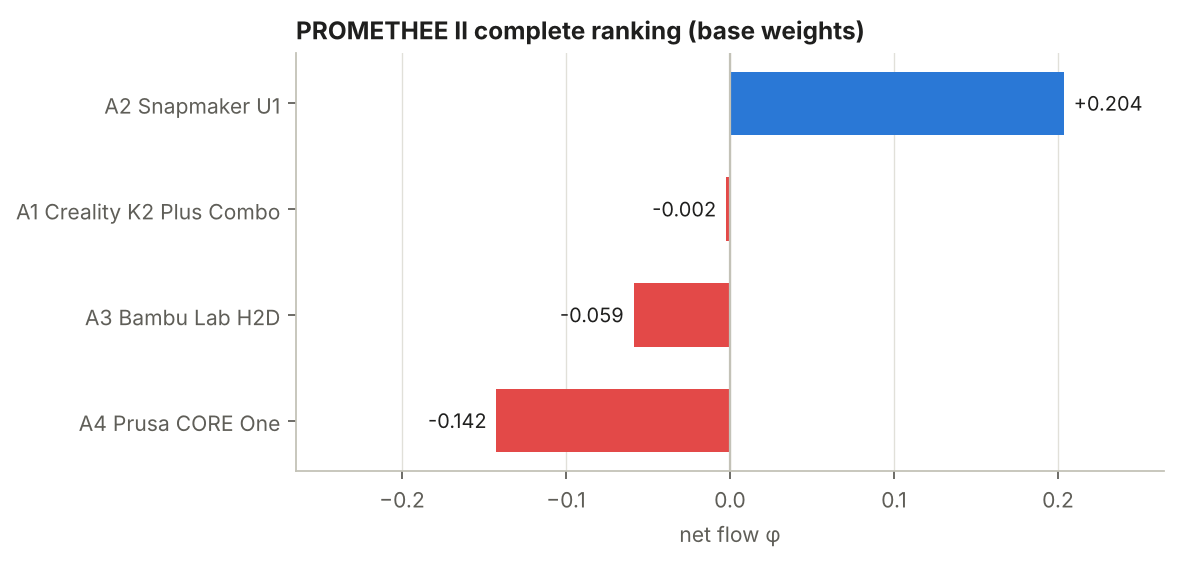

In [12]:
display(Markdown("### PROMETHEE II – flows and ranking"))
display(pd.read_csv("results/promethee_flows.csv", index_col=0).round(3))
display(Image("results/figures/01_net_flows.png", width=900))

> **Notatka:**
>
> **Kluczowy wynik.** φ⁺ = jak bardzo drukarka przewyższa inne, φ⁻ = jak bardzo inne przewyższają ją,
> **φ = φ⁺ − φ⁻** → ranking PROMETHEE II: **U1 > K2 Plus > H2D > Prusa**.
> U1 ma wyraźną przewagę (φ = +0.204), K2 i H2D są blisko siebie.

In [13]:
display(Markdown("### Aggregated preference indices π(a, b)"))
display(Markdown('π(a, b) = weighted degree to which row printer is preferred to column printer'))
display(pd.read_csv("results/preference_index_matrix.csv", index_col=0).round(3))

### Aggregated preference indices π(a, b)

π(a, b) = weighted degree to which row printer is preferred to column printer

,A1,A2,A3,A4
"pi(a,b)",,,,
A1,0.000,0.224,0.347,0.145
A2,0.420,0.000,0.467,0.451
A3,0.263,0.338,0.000,0.336
A4,0.040,0.164,0.300,0.000


> **Notatka:**
>
> Stąd biorą się przepływy. Np. **π(U1, H2D) = 0.467**: cena 0.30·1 (U1 tańsza o 1226 € > p) + dysze 0.25·(2/3).
> φ⁺(U1) = średnia z **wiersza** U1 = (0.420 + 0.467 + 0.451)/3 = 0.446;
> φ⁻(U1) = średnia z **kolumny** U1 = (0.224 + 0.338 + 0.164)/3 = 0.242.

### PROMETHEE I – partial ranking

P = row outranks column, `-` = column outranks row, R = incomparable

,A1,A2,A3,A4
a \ b,,,,
A1,=,R,R,P
A2,R,=,P,P
A3,R,-,=,R
A4,-,-,R,=


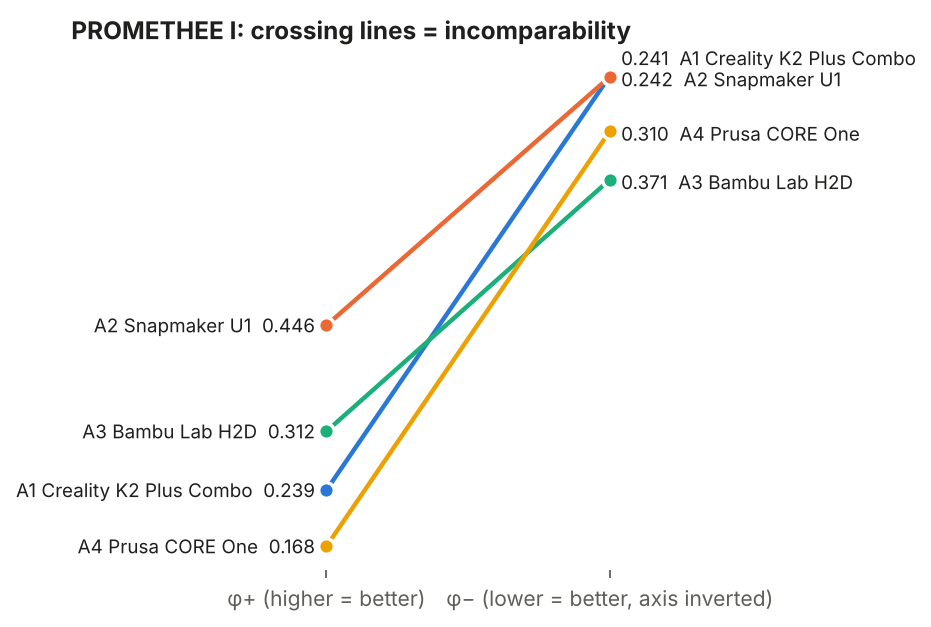

In [14]:
display(Markdown("### PROMETHEE I – partial ranking"))
display(Markdown('P = row outranks column, `-` = column outranks row, R = incomparable'))
display(pd.read_csv("results/promethee_I_relations.csv", index_col=0).round(3))
display(Image("results/figures/02_promethee_I.png", width=900))

> **Notatka:**
>
> PROMETHEE I patrzy na φ⁺ i φ⁻ **osobno**. Lepsza tylko gdy wyższe φ⁺ **i** niższe φ⁻.
> Gdy jedno mówi „lepsza”, a drugie „gorsza” → **R (nieporównywalne)**, na wykresie linie się krzyżują.
> H2D jest nieporównywalna z K2 i Prusą: świetna w wielu rzeczach, ale bardzo droga.
> U1 vs K2: R tylko przez różnicę φ⁻ = 0.001, w praktyce U1 ≥ K2.

### Unicriterion net flows (strengths / weaknesses)

,Price [EUR],Noise [dB(A)],Max speed [mm/s],Build volume [dm3],Ease of use [1-5],Nozzles [pcs]
Alternative,,,,,,
A1 Creality K2 Plus Combo,0.216,0.200,-0.286,0.798,-0.667,-0.444
A2 Snapmaker U1,0.679,-0.793,-0.429,-0.505,0.000,0.889
A3 Bambu Lab H2D,-1.000,0.260,1.000,0.407,0.667,0.000
A4 Prusa CORE One,0.104,0.333,-0.286,-0.700,0.000,-0.444


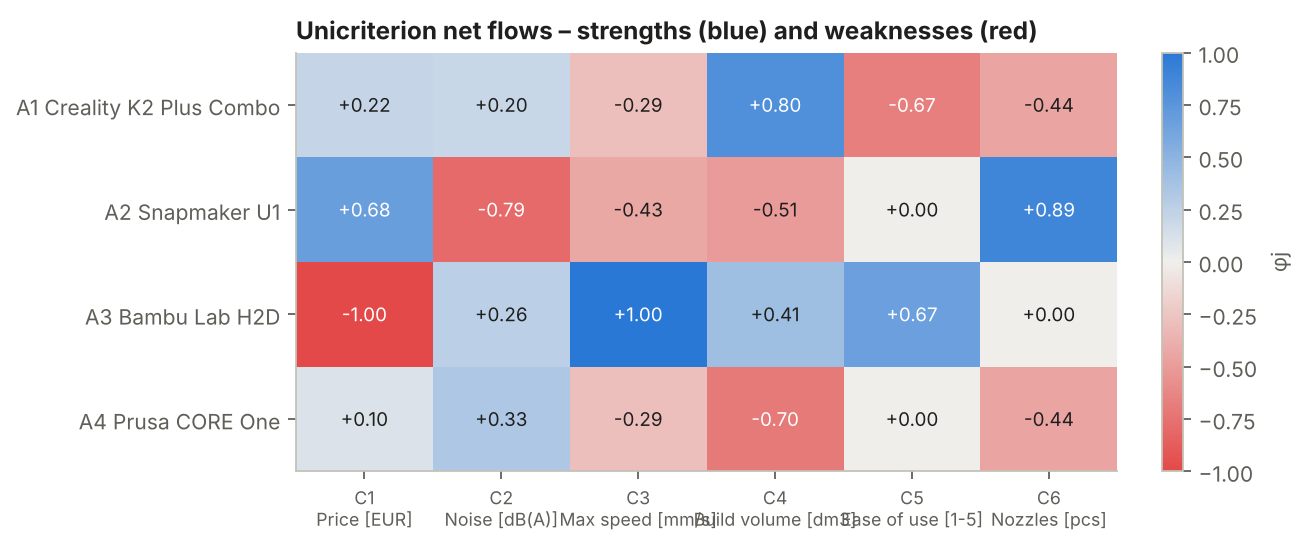

In [15]:
display(Markdown("### Unicriterion net flows (strengths / weaknesses)"))
display(pd.read_csv("results/unicriterion_net_flows.csv", index_col=0).round(3))
display(Image("results/figures/03_unicriterion_profiles.png", width=900))

> **Notatka:**
>
> φ_j = przepływ liczony tylko na jednym kryterium → **mocne (niebieskie) i słabe (czerwone) strony**.
> φ = Σ w_j·φ_j. U1 wygrywa, bo jest mocna na cenie i dyszach, czyli moich dwóch najważniejszych kryteriach (55% wagi).

## 4. Comparison of rankings (weight scenarios, PROMETHEE vs WSM P × W)

### Ranks under every method and weight scenario

,A1,A2,A3,A4
Method / weights,,,,
PROMETHEE II – M1 points (base),2,1,3,4
PROMETHEE II – M2 rank sum,2,1,3,4
PROMETHEE II – Equal (1/6 each),3,2,1,4
PROMETHEE II – 0.2 / 0.15 balanced,3,2,1,4
PROMETHEE II – Price matters less,3,2,1,4
PROMETHEE II – No multi-colour needed,1,2,4,3
PROMETHEE II – Big prints,1,3,2,4
Weighted sum (P×W) – M1 points (base),3,1,2,4
Weighted sum (P×W) – M2 rank sum,2,1,3,4


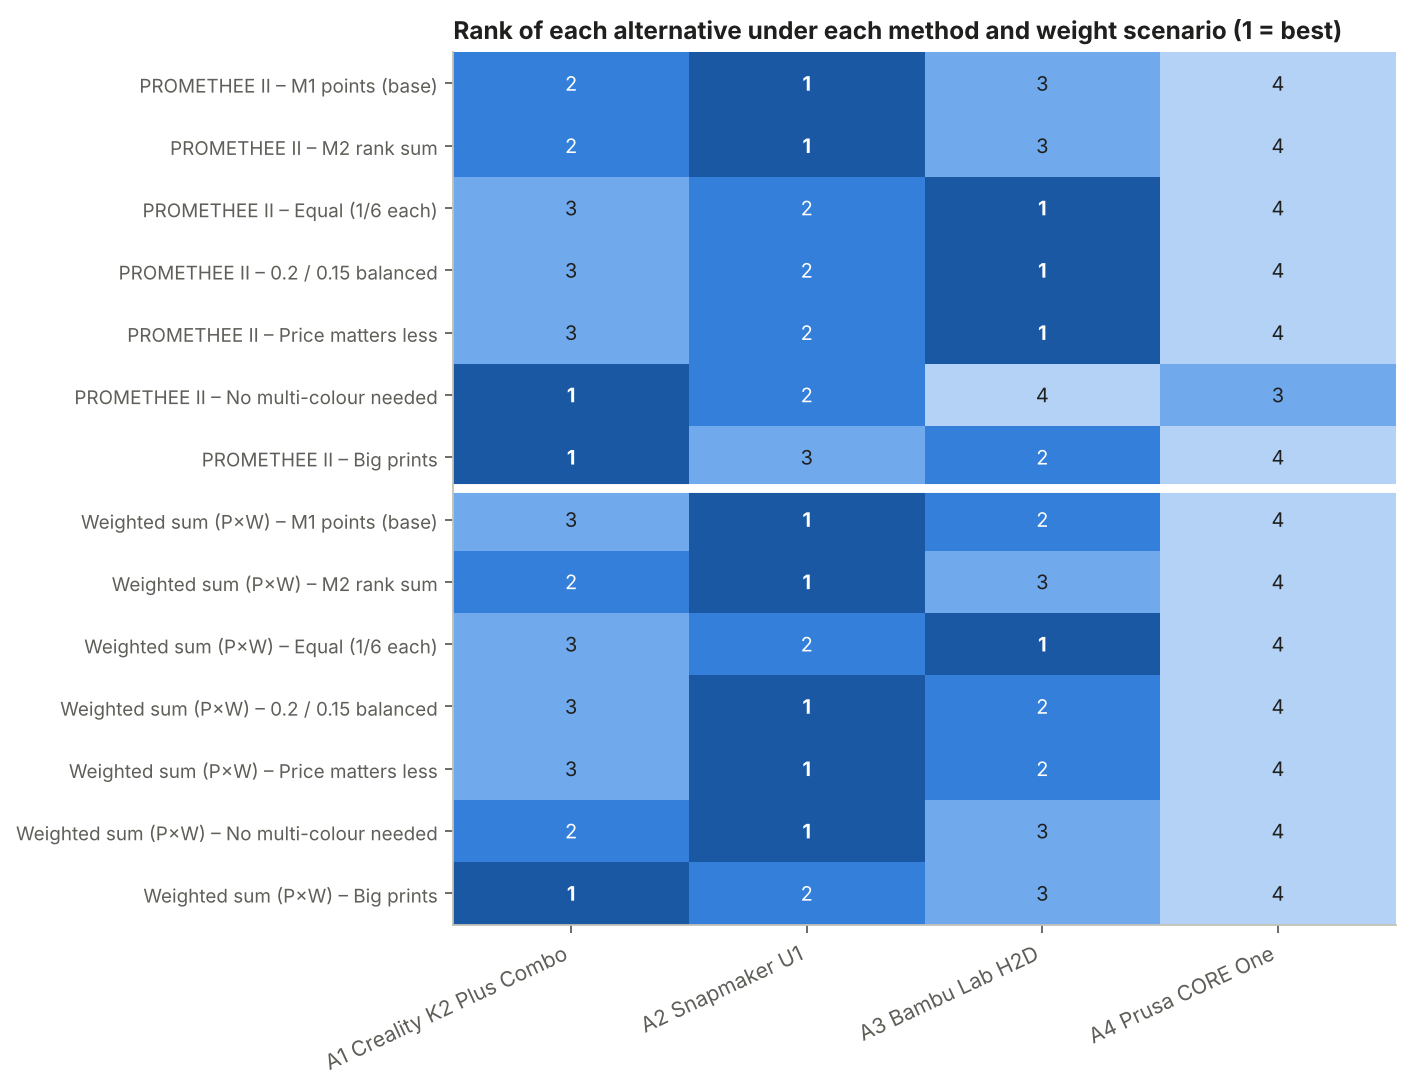

In [16]:
display(Markdown("### Ranks under every method and weight scenario"))
display(pd.read_csv("results/ranking_comparison_ranks.csv", index_col=0).round(3))
display(Image("results/figures/04_ranking_comparison.png", width=900))

> **Notatka:**
>
> Górna część = PROMETHEE, dolna = WSM z Task 1, dla 7 zestawów wag.
> - M1 i M2 → U1 w obu metodach (wynik Task 1 potwierdzony)
> - równe wagi / cena mniej ważna → H2D (PROMETHEE), WSM często dalej U1
> - bez multi-colour / duże wydruki → K2 Plus

In [17]:
display(Markdown("### Scores"))
display(Markdown('Net flow φ for PROMETHEE, Task 1 WSM score for P × W'))
display(pd.read_csv("results/ranking_comparison_scores.csv", index_col=0).round(3))

### Scores

Net flow φ for PROMETHEE, Task 1 WSM score for P × W

,A1,A2,A3,A4
Method / weights,,,,
PROMETHEE II – M1 points (base),-0.002,0.204,-0.059,-0.142
PROMETHEE II – M2 rank sum,0.049,0.142,-0.051,-0.140
PROMETHEE II – Equal (1/6 each),-0.030,-0.026,0.222,-0.165
PROMETHEE II – 0.2 / 0.15 balanced,-0.039,0.055,0.150,-0.166
PROMETHEE II – Price matters less,-0.071,0.079,0.207,-0.215
PROMETHEE II – No multi-colour needed,0.145,-0.025,-0.078,-0.042
PROMETHEE II – Big prints,0.228,-0.030,0.057,-0.255
Weighted sum (P×W) – M1 points (base),0.662,0.850,0.673,0.588
Weighted sum (P×W) – M2 rank sum,0.687,0.841,0.682,0.595


> **Notatka:**
>
> **Różnica WSM vs PROMETHEE:** WSM sumuje znormalizowane wartości (każda różnica liczy się proporcjonalnie).
> PROMETHEE porównuje **pary** i używa progów: małe różnice (< q) pomija, duże (> p) „ucina” na 1.
> Dlatego tam, gdzie WSM ledwo widzi różnicę (0.800 vs 0.799), PROMETHEE może dać wyraźny wynik.

## 5. Sensitivity analysis

### 5.1 Weight stability intervals

,criterion,weight,ranking stable from,ranking stable to,best stays best from,best stays best to
id,,,,,,
C1,Price [EUR],0.30,0.266,0.349,0.170,1.000
C2,Noise [dB(A)],0.15,0.000,0.296,0.000,0.296
C3,Max speed [mm/s],0.10,0.037,0.138,0.000,0.240
C4,Build volume [dm3],0.12,0.048,0.240,0.000,0.240
C5,Ease of use [1-5],0.08,0.000,0.117,0.000,0.340
C6,Nozzles [pcs],0.25,0.113,0.334,0.113,1.000


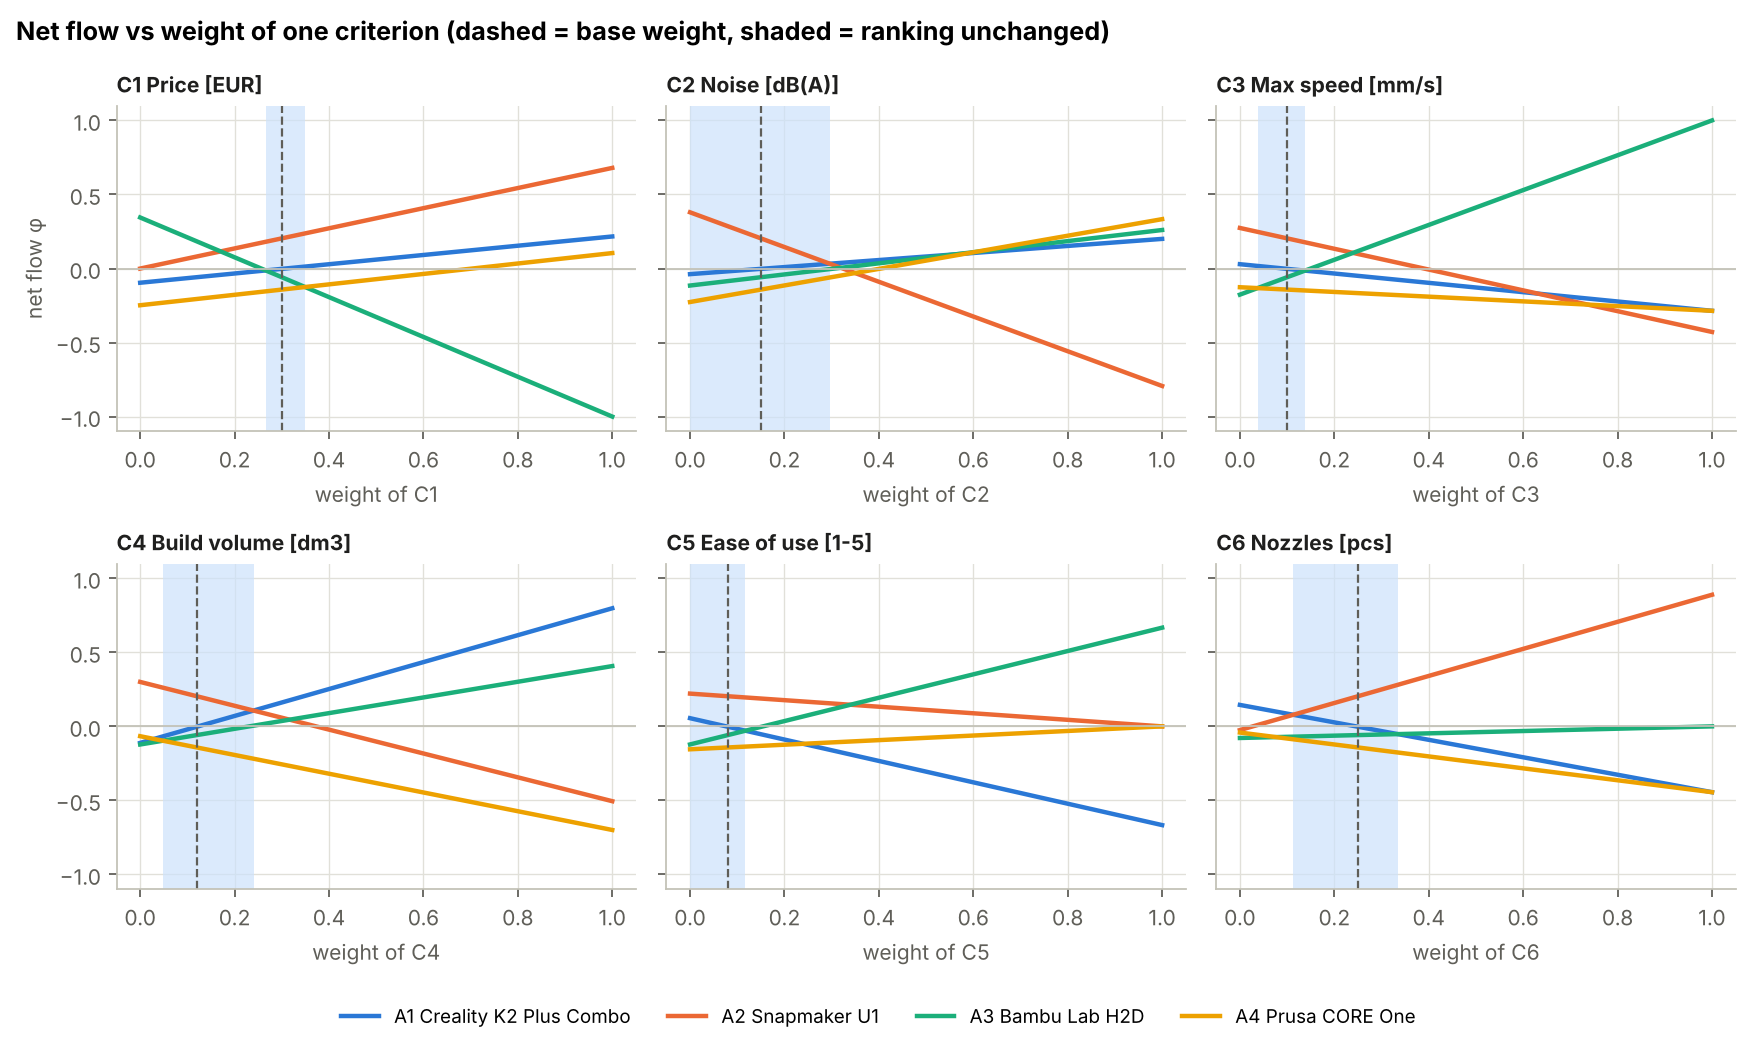

In [18]:
display(Markdown("### 5.1 Weight stability intervals"))
display(pd.read_csv("results/weight_stability_intervals.csv", index_col=0).round(3))
display(Image("results/figures/05_weight_sweeps.png", width=900))

> **Notatka:**
>
> Zmieniam wagę **jednego** kryterium (reszta proporcjonalnie). Niebieski pas = ranking się nie zmienia.
> U1 zostaje 1. dla wagi ceny ≥ 0.17 i wagi dysz ≥ 0.113, inne kryteria musiałyby mieć co najmniej 2× większą wagę.

### 5.2 Monte-Carlo rank acceptability (±20 % / ±50 % / any weights)

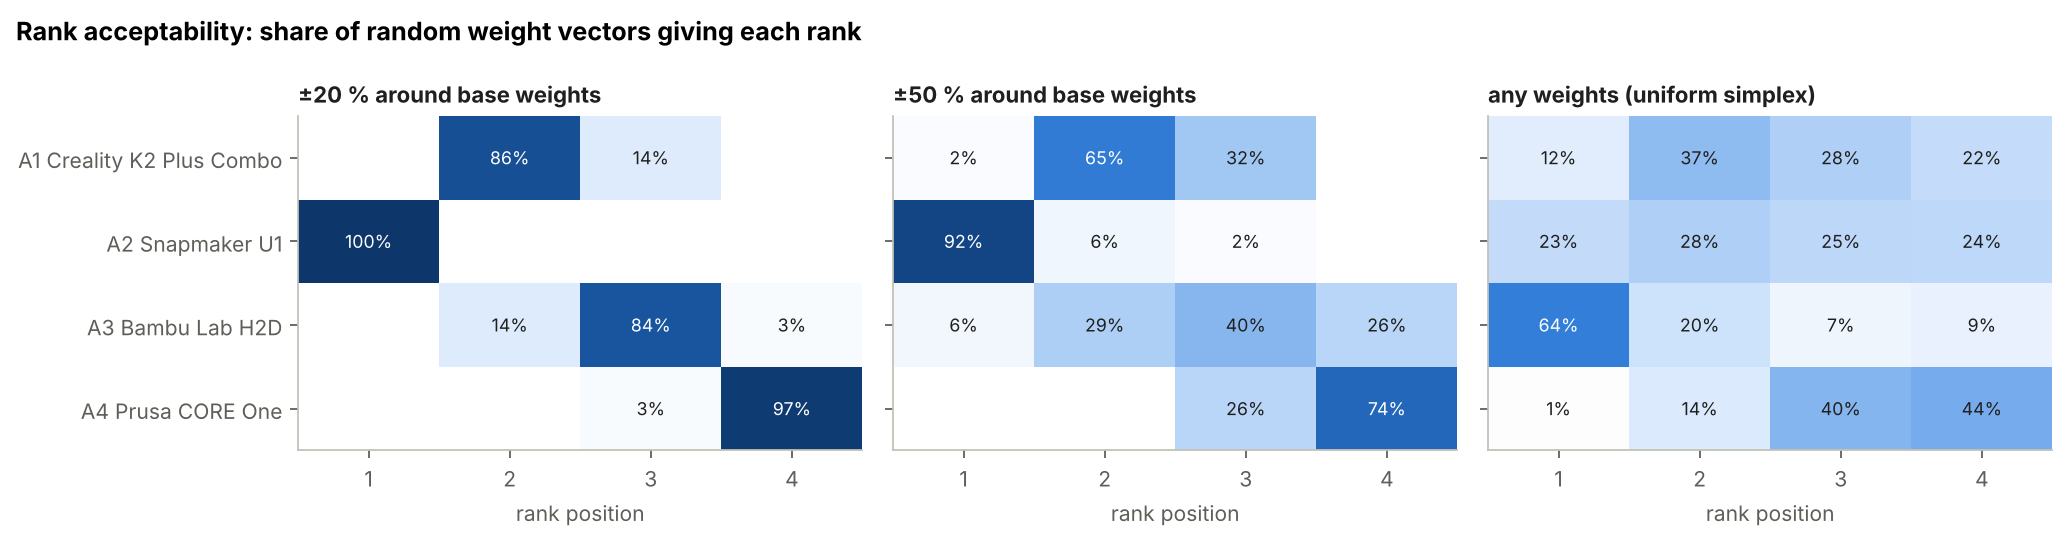

In [19]:
display(Markdown("### 5.2 Monte-Carlo rank acceptability (±20 % / ±50 % / any weights)"))
display(Image("results/figures/06_rank_acceptability.png", width=900))

> **Notatka:**
>
> Losowe wagi: ±20% wokół moich → U1 1. w 100%; ±50% → 92%; zupełnie losowe → H2D 64%.
> Czyli: **H2D to obiektywnie najmocniejsza drukarka, U1 wygrywa przez moje priorytety** (cena + dysze).

In [20]:
for f in ["local20", "local50", "simplex"]:
    display(Markdown(f"**{f}**"))
    display(pd.read_csv(f"results/rank_acceptability_{f}.csv", index_col=0).round(3))

**local20**

,rank 1,rank 2,rank 3,rank 4,mean rank
Alternative,,,,,
A1 Creality K2 Plus Combo,0.0,0.865,0.135,0.000,2.135
A2 Snapmaker U1,1.0,0.000,0.000,0.000,1.000
A3 Bambu Lab H2D,0.0,0.135,0.836,0.029,2.894
A4 Prusa CORE One,0.0,0.000,0.029,0.971,3.971


**local50**

,rank 1,rank 2,rank 3,rank 4,mean rank
Alternative,,,,,
A1 Creality K2 Plus Combo,0.025,0.653,0.322,0.000,2.297
A2 Snapmaker U1,0.917,0.059,0.024,0.000,1.107
A3 Bambu Lab H2D,0.058,0.288,0.398,0.256,2.851
A4 Prusa CORE One,0.000,0.000,0.256,0.744,3.744


**simplex**

,rank 1,rank 2,rank 3,rank 4,mean rank
Alternative,,,,,
A1 Creality K2 Plus Combo,0.121,0.374,0.282,0.223,2.607
A2 Snapmaker U1,0.228,0.283,0.246,0.243,2.505
A3 Bambu Lab H2D,0.640,0.201,0.067,0.093,1.613
A4 Prusa CORE One,0.012,0.142,0.405,0.441,3.275


### 5.3 Thresholds and preference functions

,A1,A2,A3,A4,Kendall τ vs base,best
Preference-function variant,,,,,,
thresholds x0.25,3,1,2,4,0.667,A2
thresholds x0.5,3,1,2,4,0.667,A2
thresholds x0.75,2,1,3,4,1.000,A2
thresholds x1,2,1,3,4,1.000,A2
thresholds x1.25,2,1,3,4,1.000,A2
thresholds x1.5,2,1,4,3,0.667,A2
thresholds x2,2,1,4,3,0.667,A2
all 'usual' (type I),3,1,2,4,0.667,A2


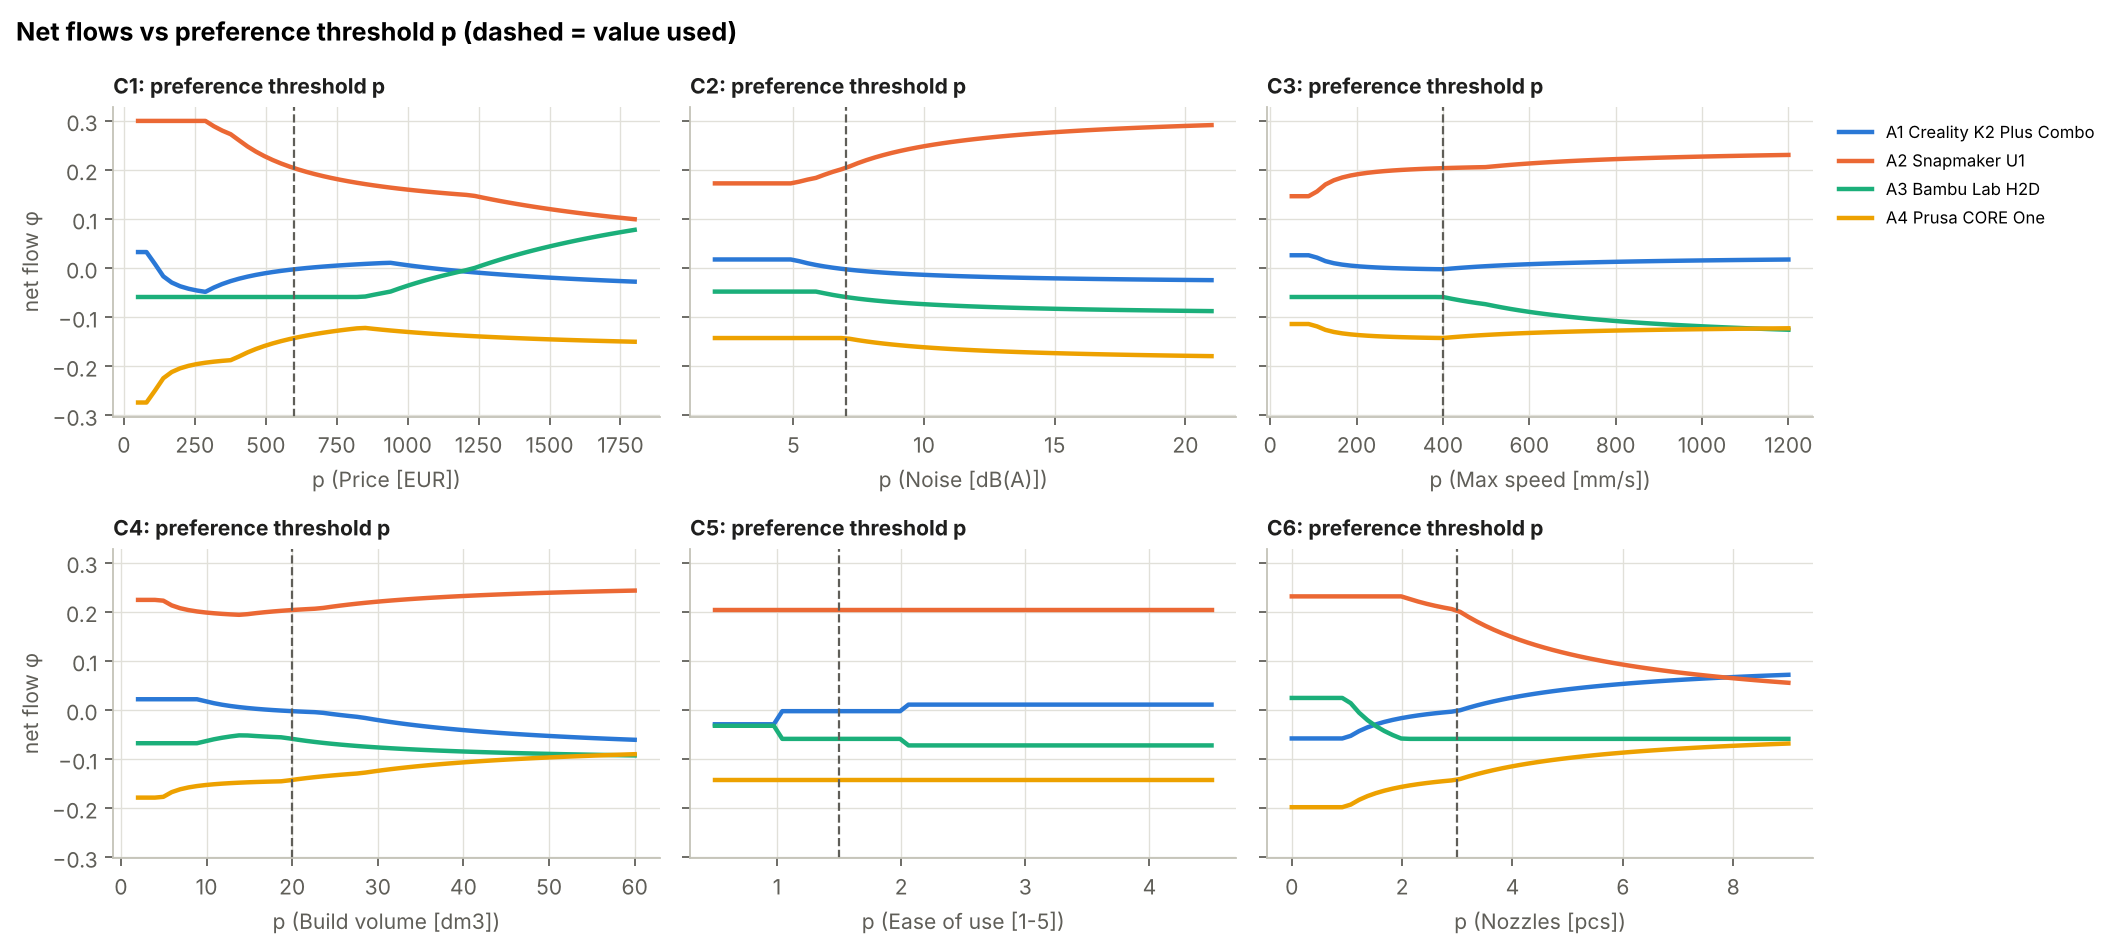

In [21]:
display(Markdown("### 5.3 Thresholds and preference functions"))
display(pd.read_csv("results/threshold_sensitivity.csv", index_col=0).round(3))
display(Image("results/figures/07_threshold_sweeps.png", width=900))

> **Notatka:**
>
> Progi q, p to moja subiektywna decyzja, więc sprawdzam: mnożę wszystkie ×0.25 … ×2 → **U1 zawsze 1.** Zmieniają się tylko miejsca 2–3.

### 5.4 What if the Bambu H2D goes on sale?

,A1,A2,A3,A4,winner,rank of A3
value,,,,,,
700.0,-0.182,0.076,0.444,-0.339,A3 Bambu Lab H2D,1
1000.0,-0.127,0.113,0.299,-0.285,A3 Bambu Lab H2D,1
1300.0,-0.091,0.167,0.166,-0.242,A2 Snapmaker U1,2
1600.0,-0.036,0.204,0.026,-0.194,A2 Snapmaker U1,2
1900.0,-0.002,0.204,-0.059,-0.142,A2 Snapmaker U1,3
2125.0,-0.002,0.204,-0.059,-0.142,A2 Snapmaker U1,3
2200.0,-0.002,0.204,-0.059,-0.142,A2 Snapmaker U1,3
2500.0,-0.002,0.204,-0.059,-0.142,A2 Snapmaker U1,3


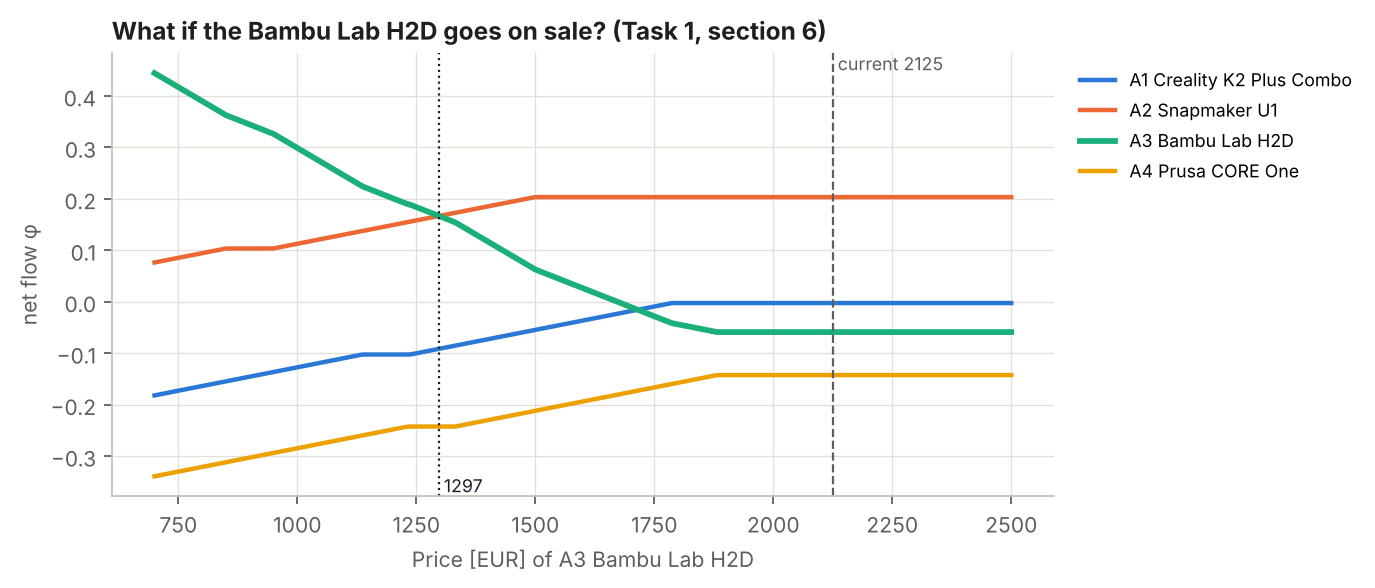

In [22]:
display(Markdown("### 5.4 What if the Bambu H2D goes on sale?"))
display(pd.read_csv("results/what_if.csv", index_col=0).round(3))
display(Image("results/figures/08_what_if.png", width=900))

> **Notatka:**
>
> Kontynuacja sekcji 6 z Task 1: H2D wygrywa, jeśli kosztuje **< ok. 1297 €**.
> WSM w Task 1 mówił, że H2D nie wygrywa nawet przy cenie U1, więc tu PROMETHEE daje inny wniosek.
> Powyżej ~1880 € linia H2D jest płaska: różnica ceny > p = 600 €, więc preferencja i tak = 1.

## 6. Extension – FlowSort (PROMETHEE SORT)

> **Notatka:**
>
> **Dlaczego SORT:** jeden decydent (więc nie grupowa), kupuję jedną drukarkę (więc nie portfolio).
> Ranking mówi tylko „kto lepszy od kogo”, FlowSort mówi, **czy drukarka jest naprawdę dobra**.
> Klasy Very good / Good / Acceptable wyznaczają 4 profile; najniższy = limity „must pass” z Task 1.

### Assignment with base weights

,φ (in R ∪ {a}),class by φ,class by φ+,class by φ−,"interval (φ+, φ−)"
Alternative,,,,,
A1 Creality K2 Plus Combo,0.096,Good,Good,Good,Good
A2 Snapmaker U1,0.237,Very good,Very good,Very good,Very good
A3 Bambu Lab H2D,0.046,Good,Good,Good,Good
A4 Prusa CORE One,-0.008,Good,Good,Good,Good


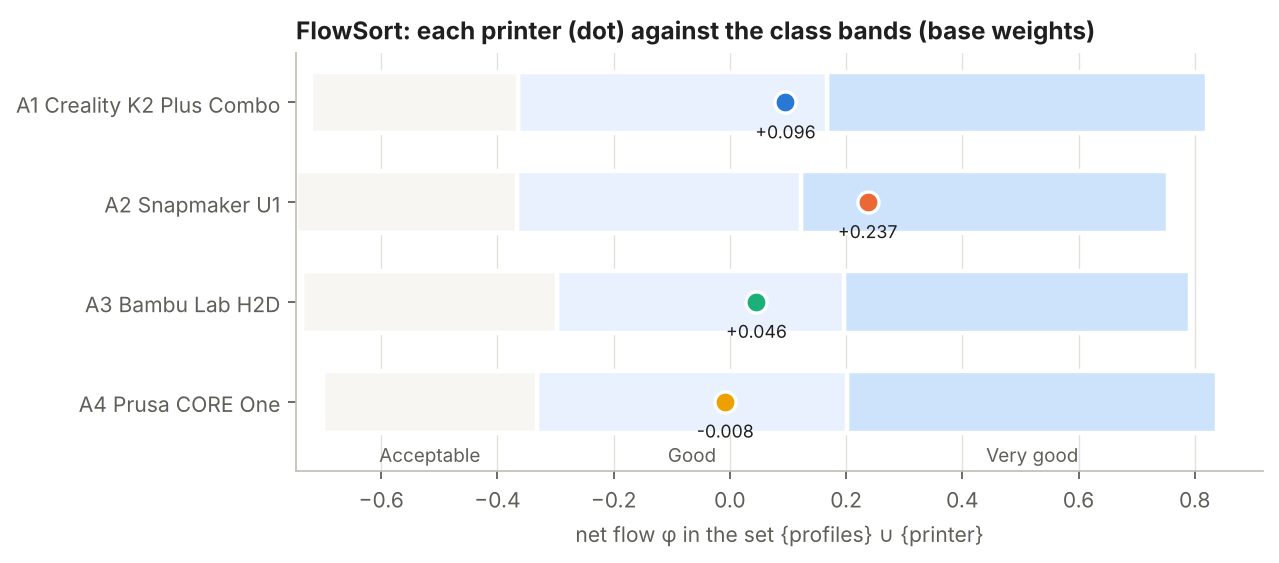

In [23]:
display(Markdown("### Assignment with base weights"))
display(pd.read_csv("results/flowsort_base.csv", index_col=0).round(3))
display(Image("results/figures/09_flowsort.png", width=900))

> **Notatka:**
>
> Tylko **U1 = Very good**, reszta Good. Żadna nie jest blisko limitów (zgodne z Task 1: wszystkie „within limits”).

In [24]:
display(Markdown("### Assignment under every weight scenario"))
display(pd.read_csv("results/flowsort_scenarios.csv", index_col=0).round(3))

### Assignment under every weight scenario

,A1 Creality K2 Plus Combo,A2 Snapmaker U1,A3 Bambu Lab H2D,A4 Prusa CORE One
Weights,,,,
M1 points (base),Good,Very good,Good,Good
M2 rank sum,Good,Very good,Good,Good
Equal (1/6 each),Good,Good,Very good,Good
0.2 / 0.15 balanced,Good,Very good,Very good,Good
Price matters less,Good,Very good,Very good,Good
No multi-colour needed,Very good,Good,Good,Good
Big prints,Very good,Good,Good,Good


### Class acceptability under random weights

,Very good (±20%),Good (±20%),Very good (±50%),Good (±50%),Very good (any w),Good (any w),Acceptable (any w)
Alternative,,,,,,,
A1 Creality K2 Plus Combo,0.0,1.0,0.033,0.967,0.304,0.680,0.016
A2 Snapmaker U1,1.0,0.0,0.936,0.064,0.358,0.642,0.000
A3 Bambu Lab H2D,0.0,1.0,0.055,0.945,0.730,0.263,0.007
A4 Prusa CORE One,0.0,1.0,0.000,1.000,0.028,0.937,0.035


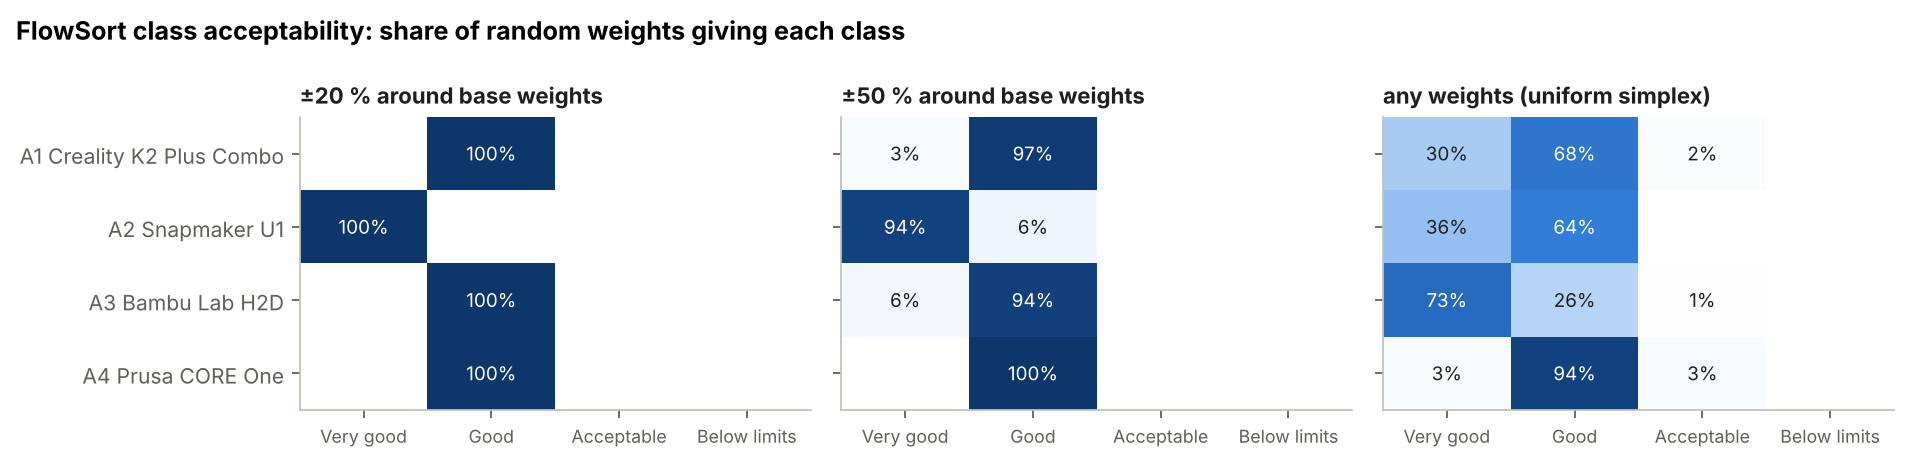

In [25]:
display(Markdown("### Class acceptability under random weights"))
display(pd.read_csv("results/flowsort_acceptability.csv", index_col=0).round(3))
display(Image("results/figures/10_flowsort_acceptability.png", width=900))

> **Notatka:**
>
> Przy ±20% wag klasy się nie zmieniają (100%). Prusa prawie nigdy nie jest Very good.

## 7. Full auto-generated results (markdown) and download

In [26]:
display(Markdown(open('results/results.md', encoding='utf-8').read()))

# Results (auto-generated) – Which 3D printer should I buy? (FDM printer for home, budget max 2500 EUR)

_Generated by `run_analysis.py`. Interpretation: see `REPORT.md`._

## 1. Input data

| Alternative | Price [EUR] | Noise [dB(A)] | Max speed [mm/s] | Build volume [dm3] | Ease of use [1-5] | Nozzles [pcs] |
|---|---|---|---|---|---|---|
| A1 Creality K2 Plus Combo | 1187 | 50 | 600 | 42.875 | 3 | 1 |
| A2 Snapmaker U1 | 899 | 55 | 500 | 19.683 | 4 | 4 |
| A3 Bambu Lab H2D | 2125 | 49.1 | 1000 | 33.8 | 5 | 2 |
| A4 Prusa CORE One | 1282 | 48 | 600 | 14.85 | 4 | 1 |

| id | criterion | direction | function | q | p | s | weight |
|---|---|---|---|---|---|---|---|
| C1 | Price [EUR] | min | linear | 50 | 600 | 0 | 0.3 |
| C2 | Noise [dB(A)] | min | linear | 2 | 7 | 0 | 0.15 |
| C3 | Max speed [mm/s] | max | linear | 50 | 400 | 0 | 0.1 |
| C4 | Build volume [dm3] | max | linear | 2 | 20 | 0 | 0.12 |
| C5 | Ease of use [1-5] | max | level | 0.5 | 1.5 | 0 | 0.08 |
| C6 | Nozzles [pcs] | max | v-shape | 0 | 3 | 0 | 0.25 |

## 2. PROMETHEE II – complete ranking

| Alternative | phi+ | phi- | phi (net) | rank |
|---|---|---|---|---|
| A2 Snapmaker U1 | 0.4457 | 0.2421 | 0.2036 | 1 |
| A1 Creality K2 Plus Combo | 0.2387 | 0.2411 | -0.0024 | 2 |
| A3 Bambu Lab H2D | 0.3125 | 0.3713 | -0.0588 | 3 |
| A4 Prusa CORE One | 0.1681 | 0.3105 | -0.1424 | 4 |

### Aggregated preference indices pi(a,b)

| pi(a,b) | A1 | A2 | A3 | A4 |
|---|---|---|---|---|
| A1 | 0.000 | 0.224 | 0.347 | 0.145 |
| A2 | 0.420 | 0.000 | 0.467 | 0.451 |
| A3 | 0.263 | 0.338 | 0.000 | 0.336 |
| A4 | 0.040 | 0.164 | 0.300 | 0.000 |

### Unicriterion net flows phi_j(a)

| Alternative | Price [EUR] | Noise [dB(A)] | Max speed [mm/s] | Build volume [dm3] | Ease of use [1-5] | Nozzles [pcs] |
|---|---|---|---|---|---|---|
| A1 Creality K2 Plus Combo | +0.216 | +0.200 | -0.286 | +0.798 | -0.667 | -0.444 |
| A2 Snapmaker U1 | +0.679 | -0.793 | -0.429 | -0.505 | +0.000 | +0.889 |
| A3 Bambu Lab H2D | -1.000 | +0.260 | +1.000 | +0.407 | +0.667 | +0.000 |
| A4 Prusa CORE One | +0.104 | +0.333 | -0.286 | -0.700 | +0.000 | -0.444 |

## 3. PROMETHEE I – partial preorder

P = row outranks column, - = column outranks row, R = incomparable, I = indifferent

| a \ b | A1 | A2 | A3 | A4 |
|---|---|---|---|---|
| A1 | = | R | R | P |
| A2 | R | = | P | P |
| A3 | R | - | = | R |
| A4 | - | - | R | = |

Incomparable pairs: A1 R A2, A1 R A3, A3 R A4

## 4. Comparison of rankings

### Weight scenarios

| Scenario | C1 | C2 | C3 | C4 | C5 | C6 |
|---|---|---|---|---|---|---|
| M1 points (base) | 0.300 | 0.150 | 0.100 | 0.120 | 0.080 | 0.250 |
| M2 rank sum | 0.286 | 0.190 | 0.095 | 0.143 | 0.048 | 0.238 |
| Equal (1/6 each) | 0.167 | 0.167 | 0.167 | 0.167 | 0.167 | 0.167 |
| 0.2 / 0.15 balanced | 0.200 | 0.150 | 0.150 | 0.150 | 0.150 | 0.200 |
| Price matters less | 0.100 | 0.190 | 0.130 | 0.150 | 0.100 | 0.330 |
| No multi-colour needed | 0.400 | 0.200 | 0.133 | 0.160 | 0.107 | 0.000 |
| Big prints | 0.250 | 0.120 | 0.080 | 0.350 | 0.080 | 0.120 |

### Ranks (1 = best)

| Method / weights | A1 | A2 | A3 | A4 |
|---|---|---|---|---|
| PROMETHEE II – M1 points (base) | 2 | 1 | 3 | 4 |
| PROMETHEE II – M2 rank sum | 2 | 1 | 3 | 4 |
| PROMETHEE II – Equal (1/6 each) | 3 | 2 | 1 | 4 |
| PROMETHEE II – 0.2 / 0.15 balanced | 3 | 2 | 1 | 4 |
| PROMETHEE II – Price matters less | 3 | 2 | 1 | 4 |
| PROMETHEE II – No multi-colour needed | 1 | 2 | 4 | 3 |
| PROMETHEE II – Big prints | 1 | 3 | 2 | 4 |
| Weighted sum (P×W) – M1 points (base) | 3 | 1 | 2 | 4 |
| Weighted sum (P×W) – M2 rank sum | 2 | 1 | 3 | 4 |
| Weighted sum (P×W) – Equal (1/6 each) | 3 | 2 | 1 | 4 |
| Weighted sum (P×W) – 0.2 / 0.15 balanced | 3 | 1 | 2 | 4 |
| Weighted sum (P×W) – Price matters less | 3 | 1 | 2 | 4 |
| Weighted sum (P×W) – No multi-colour needed | 2 | 1 | 3 | 4 |
| Weighted sum (P×W) – Big prints | 1 | 2 | 3 | 4 |

### Scores (net flow φ for PROMETHEE, WSM score with `ratio` normalisation for P×W)

| Method / weights | A1 | A2 | A3 | A4 |
|---|---|---|---|---|
| PROMETHEE II – M1 points (base) | -0.002 | +0.204 | -0.059 | -0.142 |
| PROMETHEE II – M2 rank sum | +0.049 | +0.142 | -0.051 | -0.140 |
| PROMETHEE II – Equal (1/6 each) | -0.030 | -0.026 | +0.222 | -0.165 |
| PROMETHEE II – 0.2 / 0.15 balanced | -0.039 | +0.055 | +0.150 | -0.166 |
| PROMETHEE II – Price matters less | -0.071 | +0.079 | +0.207 | -0.215 |
| PROMETHEE II – No multi-colour needed | +0.145 | -0.025 | -0.078 | -0.042 |
| PROMETHEE II – Big prints | +0.228 | -0.030 | +0.057 | -0.255 |
| Weighted sum (P×W) – M1 points (base) | +0.662 | +0.850 | +0.673 | +0.588 |
| Weighted sum (P×W) – M2 rank sum | +0.687 | +0.841 | +0.682 | +0.595 |
| Weighted sum (P×W) – Equal (1/6 each) | +0.695 | +0.772 | +0.781 | +0.616 |
| Weighted sum (P×W) – 0.2 / 0.15 balanced | +0.675 | +0.795 | +0.750 | +0.602 |
| Weighted sum (P×W) – Price matters less | +0.629 | +0.810 | +0.741 | +0.553 |
| Weighted sum (P×W) – No multi-colour needed | +0.799 | +0.800 | +0.731 | +0.701 |
| Weighted sum (P×W) – Big prints | +0.781 | +0.739 | +0.719 | +0.559 |

### Rank correlation with `PROMETHEE II – M1 points (base)`

| Method / weights | Kendall τ vs base | Spearman ρ vs base | Best |
|---|---|---|---|
| PROMETHEE II – M1 points (base) | 1.000 | 1.000 | A2 |
| PROMETHEE II – M2 rank sum | 1.000 | 1.000 | A2 |
| PROMETHEE II – Equal (1/6 each) | 0.333 | 0.400 | A3 |
| PROMETHEE II – 0.2 / 0.15 balanced | 0.333 | 0.400 | A3 |
| PROMETHEE II – Price matters less | 0.333 | 0.400 | A3 |
| PROMETHEE II – No multi-colour needed | 0.333 | 0.600 | A1 |
| PROMETHEE II – Big prints | 0.333 | 0.400 | A1 |
| Weighted sum (P×W) – M1 points (base) | 0.667 | 0.800 | A2 |
| Weighted sum (P×W) – M2 rank sum | 1.000 | 1.000 | A2 |
| Weighted sum (P×W) – Equal (1/6 each) | 0.333 | 0.400 | A3 |
| Weighted sum (P×W) – 0.2 / 0.15 balanced | 0.667 | 0.800 | A2 |
| Weighted sum (P×W) – Price matters less | 0.667 | 0.800 | A2 |
| Weighted sum (P×W) – No multi-colour needed | 1.000 | 1.000 | A2 |
| Weighted sum (P×W) – Big prints | 0.667 | 0.800 | A1 |

| Scenario | Kendall τ (PROMETHEE vs P×W) |
|---|---|
| M1 points (base) | 0.667 |
| M2 rank sum | 1.000 |
| Equal (1/6 each) | 1.000 |
| 0.2 / 0.15 balanced | 0.667 |
| Price matters less | 0.667 |
| No multi-colour needed | 0.333 |
| Big prints | 0.667 |

## 5. Sensitivity analysis

### 5.1 Weight stability intervals (exact)

Other weights keep their proportions. `best` = A2 Snapmaker U1.

| id | criterion | weight | ranking stable from | ranking stable to | best stays best from | best stays best to |
|---|---|---|---|---|---|---|
| C1 | Price [EUR] | 0.300 | 0.266 | 0.349 | 0.170 | 1.000 |
| C2 | Noise [dB(A)] | 0.150 | 0.000 | 0.296 | 0.000 | 0.296 |
| C3 | Max speed [mm/s] | 0.100 | 0.037 | 0.138 | 0.000 | 0.240 |
| C4 | Build volume [dm3] | 0.120 | 0.048 | 0.240 | 0.000 | 0.240 |
| C5 | Ease of use [1-5] | 0.080 | 0.000 | 0.117 | 0.000 | 0.340 |
| C6 | Nozzles [pcs] | 0.250 | 0.113 | 0.334 | 0.113 | 1.000 |

### 5.2 Monte-Carlo rank acceptability (20 000 weight vectors)

**(a) local: every base weight perturbed by ±20 %**

| Alternative | rank 1 | rank 2 | rank 3 | rank 4 | mean rank |
|---|---|---|---|---|---|
| A1 Creality K2 Plus Combo | 0.000 | 0.865 | 0.135 | 0.000 | 2.135 |
| A2 Snapmaker U1 | 1.000 | 0.000 | 0.000 | 0.000 | 1.000 |
| A3 Bambu Lab H2D | 0.000 | 0.135 | 0.836 | 0.029 | 2.894 |
| A4 Prusa CORE One | 0.000 | 0.000 | 0.029 | 0.971 | 3.971 |

**(b) local: every base weight perturbed by ±50 %**

| Alternative | rank 1 | rank 2 | rank 3 | rank 4 | mean rank |
|---|---|---|---|---|---|
| A1 Creality K2 Plus Combo | 0.025 | 0.653 | 0.322 | 0.000 | 2.297 |
| A2 Snapmaker U1 | 0.917 | 0.059 | 0.024 | 0.000 | 1.107 |
| A3 Bambu Lab H2D | 0.058 | 0.288 | 0.398 | 0.256 | 2.851 |
| A4 Prusa CORE One | 0.000 | 0.000 | 0.256 | 0.744 | 3.744 |

**(c) global: weights uniformly random on the whole simplex**

| Alternative | rank 1 | rank 2 | rank 3 | rank 4 | mean rank |
|---|---|---|---|---|---|
| A1 Creality K2 Plus Combo | 0.121 | 0.374 | 0.282 | 0.223 | 2.607 |
| A2 Snapmaker U1 | 0.228 | 0.283 | 0.246 | 0.243 | 2.505 |
| A3 Bambu Lab H2D | 0.640 | 0.201 | 0.067 | 0.093 | 1.613 |
| A4 Prusa CORE One | 0.012 | 0.142 | 0.405 | 0.441 | 3.275 |

### 5.3 Preference-function / threshold sensitivity (ranks)

| Preference-function variant | A1 | A2 | A3 | A4 | Kendall τ vs base | best |
|---|---|---|---|---|---|---|
| thresholds x0.25 | 3 | 1 | 2 | 4 | 0.667 | A2 |
| thresholds x0.5 | 3 | 1 | 2 | 4 | 0.667 | A2 |
| thresholds x0.75 | 2 | 1 | 3 | 4 | 1.000 | A2 |
| thresholds x1 | 2 | 1 | 3 | 4 | 1.000 | A2 |
| thresholds x1.25 | 2 | 1 | 3 | 4 | 1.000 | A2 |
| thresholds x1.5 | 2 | 1 | 4 | 3 | 0.667 | A2 |
| thresholds x2 | 2 | 1 | 4 | 3 | 0.667 | A2 |
| all 'usual' (type I) | 3 | 1 | 2 | 4 | 0.667 | A2 |

### 5.4 What-if: What if the Bambu Lab H2D goes on sale? (Task 1, section 6)

Varying `Price [EUR]` of A3 Bambu Lab H2D (current value 2125), base weights.

| value | A1 | A2 | A3 | A4 | winner | rank of A3 |
|---|---|---|---|---|---|---|
| 700.0 | -0.182 | +0.076 | +0.444 | -0.339 | A3 Bambu Lab H2D | 1 |
| 1000.0 | -0.127 | +0.113 | +0.299 | -0.285 | A3 Bambu Lab H2D | 1 |
| 1300.0 | -0.091 | +0.167 | +0.166 | -0.242 | A2 Snapmaker U1 | 2 |
| 1600.0 | -0.036 | +0.204 | +0.026 | -0.194 | A2 Snapmaker U1 | 2 |
| 1900.0 | -0.002 | +0.204 | -0.059 | -0.142 | A2 Snapmaker U1 | 3 |
| 2125.0 | -0.002 | +0.204 | -0.059 | -0.142 | A2 Snapmaker U1 | 3 |
| 2200.0 | -0.002 | +0.204 | -0.059 | -0.142 | A2 Snapmaker U1 | 3 |
| 2500.0 | -0.002 | +0.204 | -0.059 | -0.142 | A2 Snapmaker U1 | 3 |

Winner changes at: 1297

## 6. Extension – FlowSort (PROMETHEE sorting)

FlowSort: assign each printer to a quality class using limiting profiles. The worst profile is the Task 1 'must pass' limits.

### Limiting profiles

| Limiting profile | Price [EUR] | Noise [dB(A)] | Max speed [mm/s] | Build volume [dm3] | Ease of use [1-5] | Nozzles [pcs] |
|---|---|---|---|---|---|---|
| r1 ideal (best value in budget) | 800 | 45 | 1000 | 45 | 5 | 4 |
| r2 very good / good | 1200 | 50 | 650 | 30 | 4 | 2 |
| r3 good / acceptable | 1800 | 55 | 450 | 20 | 3.5 | 1.5 |
| r4 must-pass limits (Task 1) | 2500 | 60 | 300 | 14 | 3 | 1 |

### Assignment with base weights

| Alternative | φ (in R ∪ {a}) | class by φ | class by φ+ | class by φ− | interval (φ+, φ−) |
|---|---|---|---|---|---|
| A1 Creality K2 Plus Combo | +0.096 | Good | Good | Good | Good |
| A2 Snapmaker U1 | +0.237 | Very good | Very good | Very good | Very good |
| A3 Bambu Lab H2D | +0.046 | Good | Good | Good | Good |
| A4 Prusa CORE One | -0.008 | Good | Good | Good | Good |

Net flows of the profiles in each sorting run:

| flows of profiles when sorting | r1 ideal (best value in budget) | r2 very good / good | r3 good / acceptable | r4 must-pass limits (Task 1) |
|---|---|---|---|---|
| A1 Creality K2 Plus Combo | +0.821 | +0.168 | -0.364 | -0.720 |
| A2 Snapmaker U1 | +0.754 | +0.123 | -0.367 | -0.747 |
| A3 Bambu Lab H2D | +0.792 | +0.196 | -0.297 | -0.737 |
| A4 Prusa CORE One | +0.838 | +0.202 | -0.333 | -0.700 |

### Assignment under every weight scenario

| Weights | A1 Creality K2 Plus Combo | A2 Snapmaker U1 | A3 Bambu Lab H2D | A4 Prusa CORE One |
|---|---|---|---|---|
| M1 points (base) | Good | Very good | Good | Good |
| M2 rank sum | Good | Very good | Good | Good |
| Equal (1/6 each) | Good | Good | Very good | Good |
| 0.2 / 0.15 balanced | Good | Very good | Very good | Good |
| Price matters less | Good | Very good | Very good | Good |
| No multi-colour needed | Very good | Good | Good | Good |
| Big prints | Very good | Good | Good | Good |

### Class acceptability (5 000 random weight vectors each)

| Alternative | Very good (±20%) | Good (±20%) | Very good (±50%) | Good (±50%) | Very good (any w) | Good (any w) | Acceptable (any w) |
|---|---|---|---|---|---|---|---|
| A1 Creality K2 Plus Combo | 0.000 | 1.000 | 0.033 | 0.967 | 0.304 | 0.680 | 0.016 |
| A2 Snapmaker U1 | 1.000 | 0.000 | 0.936 | 0.064 | 0.358 | 0.642 | 0.000 |
| A3 Bambu Lab H2D | 0.000 | 1.000 | 0.055 | 0.945 | 0.730 | 0.263 | 0.007 |
| A4 Prusa CORE One | 0.000 | 1.000 | 0.000 | 1.000 | 0.028 | 0.937 | 0.035 |


In [27]:
# optional: download all tables and figures as a zip
import shutil
shutil.make_archive('promethee_results', 'zip', 'results')
try:
    from google.colab import files
    files.download('promethee_results.zip')
except ImportError:
    print('saved promethee_results.zip')

saved promethee_results.zip
